In [105]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from scipy.stats import ks_2samp, norm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from polars.testing import assert_frame_equal

import TS_fitter as tsf
import read_spt3g_fits as spt3g
import plotting_functions as pltfun
import dataset
import fitter_validation as fv
import evaluation as ev
import load_db as db

pl.Config.set_tbl_rows(50)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


polars.config.Config

# ML testing

### just a quick look at the data before we get going

In [7]:
data_dir = 'data'
image_dir = 'images'
for folder in [data_dir, f"{image_dir}/validation", f"{image_dir}/evaluation"]:
    os.makedirs(folder, exist_ok=True)

lightcurves = spt3g.read_lightcurves(f"{data_dir}/spt3g_flare_lightcurves_2019_2022.fits")
# the catalog's ts is the real pipeline's TS at the detection pixel, so call it ts_published
catalog = (pl.read_csv(f"{data_dir}/spt3g_2019_2022_flare_star_catalog.csv",
                       schema_overrides={'dr3_source_id': pl.Utf8})
           .rename({'ts': 'ts_published'}))

# the slow TS fits are saved to data/ the first time and loaded after that.
# set refit = True to redo them from scratch
refit = False

def load_or_run(path, run):
    """Loads a saved result from path, or runs run() and saves it there if there isn't one (or refit is True)."""
    if os.path.exists(path) and not refit:
        return pl.read_parquet(path)
    result = run()
    result.write_parquet(path)
    return result

# outputs of dataset.window_features(), the per-window fit results
window_feature_columns = ['ts', 'fwhm_d', 't0_rel_d', 'snr_amp_95', 'snr_amp_150', 'fwhm_at_bound',
                          'n_good', 'span_d', 'null_chi2_red', 'n_3sigma_both', 'peak_snr']

In [42]:
lightcurves.sample(10)

spt_id,gaia_id,ra,dec,mjd,flux_95,err_95,flux_150,err_150
str,str,f64,f64,f64,f64,f64,f64,f64
"""SPT-SV J023652.1-520302""","""4745195905754074496""",39.217404,-52.050702,59019.051343,-3.015038,8.22244,-6.371204,7.967013
"""SPT-SV J213023.8-601210""","""6452221724017193216""",322.599347,-60.203009,59784.524699,-0.883246,7.279618,9.999068,7.050366
"""SPT-SV J021330.9-465445""","""4942856382389905408""",33.3788,-46.912648,59898.792847,4.934698,8.203928,5.967558,8.631936
"""SPT-SV J011339.9-593934""","""4909009394396454144""",18.416603,-59.659573,59168.363657,-4.731919,6.637101,4.331353,7.284991
"""SPT-SV J023947.9-425304""","""4946915641880235904""",39.949888,-42.884468,59079.972315,-7.675015,8.129354,-0.340492,8.432524
"""SPT-SV J002127.9-635110""","""4900780511935295872""",5.366405,-63.85286,58613.706319,-8.48614,7.584948,-10.022172,7.449642
"""SPT-SV J030826.1-592224""","""4723685987981062656""",47.108807,-59.373508,59063.889792,-15.640441,7.267785,-2.720525,7.235144
"""SPT-SV J213544.8-421833""","""6577998398172195840""",323.936754,-42.309262,59151.042801,1.71344,8.038105,14.872569,8.833383
"""SPT-SV J213544.8-421833""","""6577998398172195840""",323.936754,-42.309262,59763.824907,0.496618,8.418371,-7.23101,8.450958


In [43]:
catalog.sample(10)

spt_id,mjd,ts_published,ra,dec,95_flux,95_flux_err,150_flux,150_flux_err,220_flux,220_flux_err,spectral_index_95_150,spectral_index_95_150_err,spectral_index_150_220,spectral_index_150_220_err,dr3_source_id,p-value,source_ra,source_dec,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,parallax,parallax_err,binary,2rxs_id,2rxs_ref,2rxs_flux
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,bool,str,str,f64
"""SPT-SV J205947.4-480955""",59871.16,87.683692,314.94784,-48.165488,50.266604,8.391144,66.578115,8.494336,76.384812,29.203442,0.615282,0.459993,0.358775,1.052362,"""6481430353489019776""",0.005717,314.946487,-48.165349,14.142103,16.082415,12.828092,11.94507,0.036899,false,null,null,null
"""SPT-SV J004210.2-544444""",59763.23,198.45304,10.542729,-54.745558,75.727653,7.837285,86.901656,8.094065,45.489396,28.72456,0.301327,0.30483,-1.690107,1.666583,"""4920732799689111424""",0.00242,10.542823,-54.745587,12.678206,14.20981,11.468059,22.784885,0.024119,false,"""2RXS J004213.3-544425""","""Freund""",0.0
"""SPT-SV J210120.9-493311""",59776.63,574.145128,315.337436,-49.553164,107.924726,7.695152,149.584676,7.688971,131.629893,28.20704,0.714664,0.192438,-0.333867,0.575388,"""6478107251392112640""",0.000417,315.338057,-49.552103,10.613663,11.310298,9.809847,4.379431,0.021967,true,"""2RXS J210121.1-493324""","""Freund""",0.0
"""SPT-SV J021008.5-543043""",59526.67,992.809373,32.535502,-54.511982,164.483894,7.511199,176.534891,7.724254,103.95563,27.696307,0.154799,0.138463,-1.382676,0.704958,"""4743636248509810944""",0.000685,32.533261,-54.511077,9.731695,10.317272,8.997075,4.834732,0.03874,false,"""2RXS J021008.2-543037""","""Freund""",0.0
"""SPT-SV J225726.8-564528""",58595.56,53.745787,344.36176,-56.758032,39.146352,8.071251,33.993445,8.062662,91.746758,28.180325,-0.309003,0.688047,2.592388,1.01326,"""6493575352770287488""",0.001467,344.358736,-56.761451,10.236932,10.630301,9.670088,2.817327,0.013691,true,"""2RXS J225725.0-564545""","""Freund""",0.0
"""SPT-SV J204420.3-535112""",58966.06,48.178085,311.084824,-53.853553,37.04674,7.897034,35.691535,8.771831,12.97378,33.699964,-0.08159,0.712262,-2.642307,6.812526,"""6471134835842209792""",0.000285,311.087248,-53.850918,10.082267,10.651243,9.357035,2.764819,0.017666,true,"""2RXS J204420.2-535112""","""Freund""",0.0
"""SPT-SV J211123.8-522034""",59714.85,111.997611,317.849296,-52.3429,48.012332,7.831016,72.578103,7.887844,105.081576,29.002973,0.904648,0.429103,0.966269,0.774509,"""6464757870268513152""",0.00021,317.84487,-52.33918,7.095778,7.162995,6.391891,19.359006,0.053625,true,"""2RXS J211123.4-522015""","""Freund""",0.0
"""SPT-SV J223837.1-633418""",59726.28,110.914493,339.654586,-63.571908,49.496269,10.083852,79.811254,9.480795,61.579599,35.148411,1.045996,0.516317,-0.677126,1.522251,"""6404861806838482944""",0.00023,339.648916,-63.572703,8.725044,9.226127,8.054096,2.765929,0.014588,true,"""2RXS J223836.2-633439""","""Freund""",0.0
"""SPT-SV J021007.2-543039""",59839.07,90.145546,32.530007,-54.510897,57.901267,7.490505,34.007092,7.595292,55.062835,27.042073,-1.165102,0.565081,1.258265,1.40868,"""4743636248509810944""",0.000492,32.533261,-54.511077,9.731695,10.317272,8.997075,4.834732,0.03874,false,"""2RXS J021008.2-543037""","""Freund""",0.0


## phase 1: validation

In [11]:
# quick test on the first catalog event before running everything
event = catalog.row(0, named=True)
time_arr, flux_arr, err_arr, t_ref = spt3g.format_data_fits(
    lightcurves, event['dr3_source_id'], event['mjd'] - 6.0
)
TS, t0, fwhm, amps, amp_errs, surface_map = tsf.ts_fit(time_arr, flux_arr, err_arr)
print(f"published TS {event['ts_published']:.1f}, refit TS {TS:.1f}, FWHM {fwhm * 24:.2f} hr")

published TS 614.7, refit TS 623.3, FWHM 10.23 hr


In [12]:
# the pipeline's window grid starts somewhere we don't know, so scan the starting phase and see which
# one reproduces the published TS best
t_first = lightcurves['mjd'].min()

for phase in np.arange(0, 6, 0.5):
    n, s = fv.validation_score(fv.run_validation(catalog, lightcurves, anchor=t_first + phase))
    print(f"phase {phase:.1f} d: {n} events, median |log ratio| {s:.4f}")

  0%|          | 0/111 [00:00<?, ?it/s]

phase 0.0 d: 109 events, median |log ratio| 0.0209


  0%|          | 0/111 [00:00<?, ?it/s]

phase 0.5 d: 109 events, median |log ratio| 0.0209


  0%|          | 0/111 [00:00<?, ?it/s]

...

phase 4.5 d: 110 events, median |log ratio| 0.0208


  0%|          | 0/111 [00:00<?, ?it/s]

J212756.4-670242_59175.55 no window with enough good points, skipped
phase 5.0 d: 109 events, median |log ratio| 0.0209


  0%|          | 0/111 [00:00<?, ?it/s]

phase 5.5 d: 109 events, median |log ratio| 0.0209


In [ ]:
# looks like there's an issue with one of the flares that's not being caught. seems like the data is missing somewhere?
# let's start with a 2.5d offset for the phase as that recovered 110 events and also has scored the lowest (~2% difference compared to
# the published pipeline values). the exact value doesn't matter too much, we could have easily picked 1.0, 3.0, 4.5, etc.

anchor_offset = 2.5
fixed_anchor = t_first + anchor_offset
validation = fv.run_validation(catalog, lightcurves, anchor=fixed_anchor,
                               plot_dir=f"{image_dir}/validation") # check images directory to view plots

  0%|          | 0/111 [00:00<?, ?it/s]

In [119]:
t0_max_offset = 1.5  # make sure the fitter didn't accidentally find a peak further than this offset compared to published value

validation = validation.with_columns(
    (pl.col('ts_refit') / pl.col('ts_published')).alias('ts_ratio'),
    pl.when(~pl.col('has_peak_obs')).then(pl.lit('detection obs missing'))
      .when(pl.col('t0_offset_d').abs() > t0_max_offset).then(pl.lit('fit t0 far from catalog epoch'))
      .otherwise(pl.lit(None)).alias('exclude_reason'),
)

clean = validation.filter(pl.col('exclude_reason').is_null())
excluded = validation.filter(pl.col('exclude_reason').is_not_null())
ratio = clean['ts_ratio'].to_numpy()
print(f"{clean.height}/{validation.height} events used")
print(f"median refit/published TS: {np.median(ratio):.3f}")
print(f"16-84th percentile: {np.percentile(ratio, 16):.3f}-{np.percentile(ratio, 84):.3f}")
print(f"within 5%: {(np.abs(ratio - 1) < 0.05).mean():.0%}")
print(excluded.select('spt_id', 'mjd', 'ts_published', 'ts_refit', 't0_offset_d', 'exclude_reason'))

110/111 events used
median refit/published TS: 0.992
16-84th percentile: 0.904-1.004
within 5%: 66%
shape: (1, 6)
┌──────────────────┬──────────┬──────────────┬───────────┬─────────────┬───────────────────────┐
│ spt_id           ┆ mjd      ┆ ts_published ┆ ts_refit  ┆ t0_offset_d ┆ exclude_reason        │
│ ---              ┆ ---      ┆ ---          ┆ ---       ┆ ---         ┆ ---                   │
│ str              ┆ f64      ┆ f64          ┆ f64       ┆ f64         ┆ str                   │
╞══════════════════╪══════════╪══════════════╪═══════════╪═════════════╪═══════════════════════╡
│ SPT-SV           ┆ 59003.11 ┆ 156.156242   ┆ 23.022832 ┆ 7.586215    ┆ detection obs missing │
│ J212043.7-543755 ┆          ┆              ┆           ┆             ┆                       │
└──────────────────┴──────────┴──────────────┴───────────┴─────────────┴───────────────────────┘


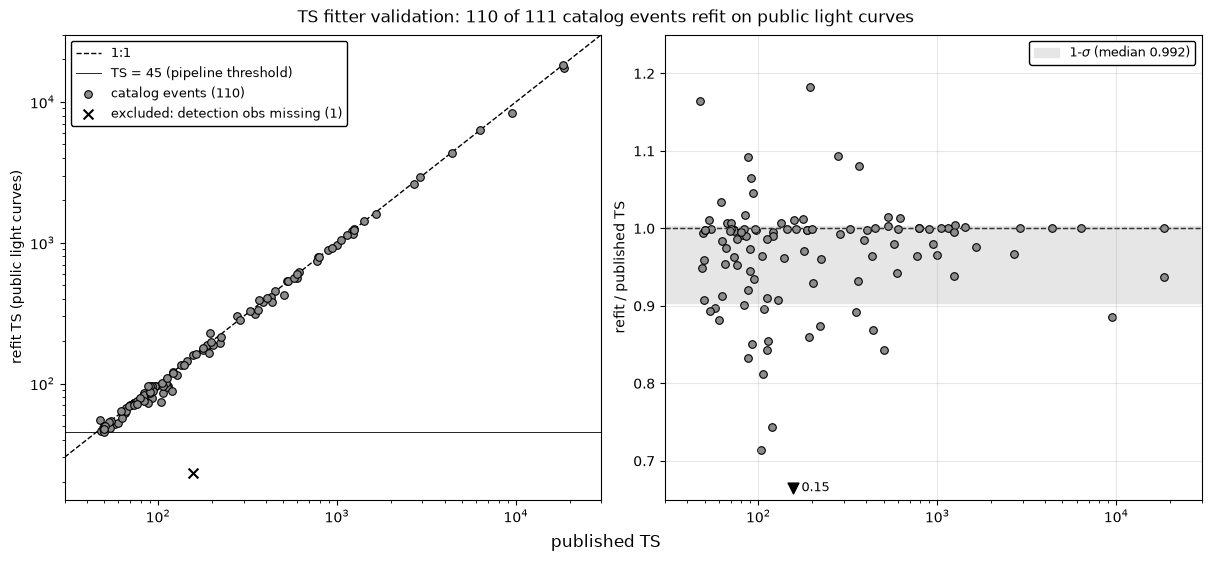

In [120]:
# refit vs published TS for the catalog events (left), and their ratio (right), which shows the agreement that a
# log-log plot over three decades hides. excluded events are marked by why they were left out
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, layout='constrained')
ts_range = [30, 3e4]

ax = axes[0]
ax.plot(ts_range, ts_range, color='k', ls='--', lw=1, zorder=0, label='1:1')
ax.axhline(45, color='k', lw=0.6, zorder=0, label='TS = 45 (pipeline threshold)')
ax.scatter(clean['ts_published'], clean['ts_refit'], s=30, color='0.55', edgecolor='k', lw=0.8,
           label=f"catalog events ({clean.height})")
for reason, group in excluded.group_by('exclude_reason'):
    ax.scatter(group['ts_published'], group['ts_refit'], s=50, marker='x', color='k', lw=1.5,
               label=f"excluded: {reason[0]} ({group.height})")
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(ts_range)
ax.set_ylim(15, 3e4)
ax.set_ylabel('refit TS (public light curves)')
ax.legend(loc='upper left', fontsize=9, edgecolor='k', framealpha=1)

ax = axes[1]
ax.axhspan(np.percentile(ratio, 16), np.percentile(ratio, 84), color='0.9', zorder=0,
           label=f"1-$\\sigma$ (median {np.median(ratio):.3f})")
ax.axhline(1, color='k', ls='--', lw=1, zorder=0)
ax.scatter(clean['ts_published'], clean['ts_refit'] / clean['ts_published'], s=30, color='0.55', edgecolor='k', lw=0.8)
ratio_ylim = (0.65, 1.25)
for row in excluded.iter_rows(named=True):
    excluded_ratio = row['ts_refit'] / row['ts_published']
    if excluded_ratio < ratio_ylim[0]:
        # off-scale: arrow at the bottom edge, labeled with the actual ratio
        ax.scatter(row['ts_published'], ratio_ylim[0] + 0.015, s=60, marker='v', color='k')
        ax.annotate(f"{excluded_ratio:.2f}", (row['ts_published'], ratio_ylim[0] + 0.015), xytext=(6, 0),
                    textcoords='offset points', va='center', fontsize=9)
    else:
        ax.scatter(row['ts_published'], excluded_ratio, s=50, marker='x', color='k', lw=1.5)
ax.set_ylim(ratio_ylim)
ax.set_ylabel('refit / published TS')
ax.legend(loc='upper right', fontsize=9, edgecolor='k', framealpha=1)
ax.grid(alpha=0.3)

fig.supxlabel('published TS')
fig.suptitle(f"TS fitter validation: {clean.height} of {validation.height} catalog events refit on public light curves")
plt.savefig(f"{image_dir}/validation/ts_validation.png", dpi=150, bbox_inches='tight')

In [16]:
# any validated events that the refit puts below the threshold?
clean.filter(pl.col('ts_refit') < 45).select('spt_id', 'mjd', 'ts_published', 'ts_refit')

spt_id,mjd,ts_published,ts_refit
str,f64,f64,f64


In [17]:
validation.write_parquet(f"{data_dir}/validation.parquet")

## phase 2: dataset (quiescent windows and injections)

In [18]:
# known flares: the catalog plus Guns, Tandoi et al. (2026) flare 5, which isn't in the catalog
known_flares = pl.concat([
    catalog.select('dr3_source_id', 'mjd'),
    pl.DataFrame({'dr3_source_id': ['6456528236185330816'], 'mjd': [59083.43]}),
])
# windows within 6 days (one stride) of a known flare are contaminated, which also removes decay tails
all_windows = dataset.enumerate_windows(lightcurves, known_flares, fixed_anchor, flare_margin=6.0)
quiet = all_windows.filter(~pl.col('contaminated'))
print(all_windows.select(pl.len().alias('N'), pl.col('contaminated').sum().alias('N_contaminated')))

shape: (1, 2)
┌───────┬────────────────┐
│ N     ┆ N_contaminated │
│ ---   ┆ ---            │
│ u32   ┆ u32            │
╞═══════╪════════════════╡
│ 11080 ┆ 427            │
└───────┴────────────────┘


In [44]:
# TS fit of every quiescent window: the noise-only (null) distribution and the classifier negatives
null_fits = (load_or_run(f"{data_dir}/null_fits.parquet", lambda: dataset.fit_windows(quiet, lightcurves))
             .select('gaia_id', 'window_start', *window_feature_columns)
             .sort('gaia_id', 'window_start'))
assert null_fits.height == quiet.height, 'saved null fits are from different windows; rerun with refit = True'
null_fits.shape, null_fits.sample(10)

((10653, 13),
 shape: (10, 13)
 ┌────────────┬───────────┬───────────┬──────────┬───┬───────────┬───────────┬───────────┬──────────┐
 │ gaia_id    ┆ window_st ┆ ts        ┆ fwhm_d   ┆ … ┆ span_d    ┆ null_chi2 ┆ n_3sigma_ ┆ peak_snr │
 │ ---        ┆ art       ┆ ---       ┆ ---      ┆   ┆ ---       ┆ _red      ┆ both      ┆ ---      │
 │ str        ┆ ---       ┆ f64       ┆ f64      ┆   ┆ f64       ┆ ---       ┆ ---       ┆ f64      │
 │            ┆ f64       ┆           ┆          ┆   ┆           ┆ f64       ┆ i64       ┆          │
 ╞════════════╪═══════════╪═══════════╪══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
 │ 6375292709 ┆ 59352.782 ┆ 3.835366  ┆ 2.70062  ┆ … ┆ 9.358218  ┆ 0.912325  ┆ 0         ┆ 2.31727  │
 │ 353220992  ┆ 153       ┆           ┆          ┆   ┆           ┆           ┆           ┆          │
 │ 4909009394 ┆ 58722.782 ┆ 7.757138  ┆ 3.616488 ┆ … ┆ 10.878426 ┆ 1.287583  ┆ 0         ┆ 2.313445 │
 │ 396454144  ┆ 153       ┆           ┆          ┆ 

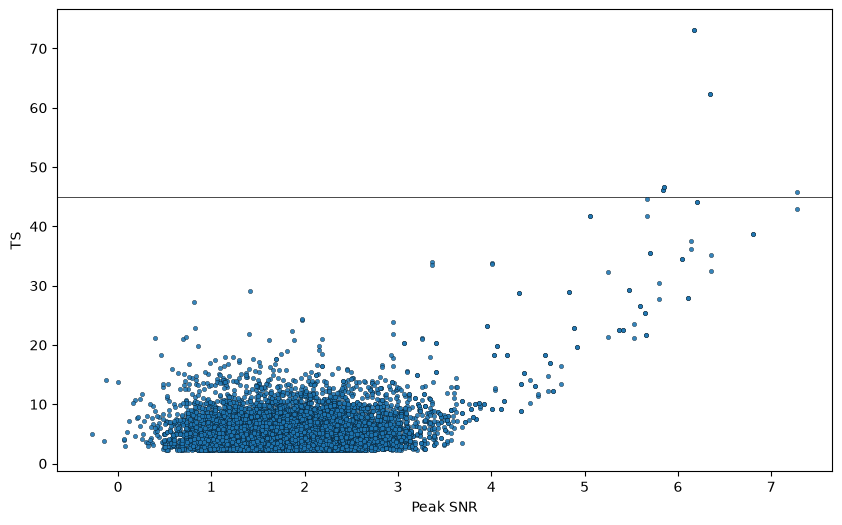

In [ ]:
# we should see two populations: 
#   -an actual outlier bright point (chance noise fluctuations, real events) where TS is correleated with SNR
#   -an uncorrelated cloud where there was no "peak" bright observation and the fitter latched on to some low/wide gaussian bump

plt.figure(figsize=(10,6))
plt.scatter(null_fits['peak_snr'], null_fits['ts'], s=10, ec='k', lw=0.25, alpha=0.9)
plt.ylabel('TS')
plt.xlabel('Peak SNR')
plt.axhline(45, c='k', zorder=0, lw=0.5, label='TS=45 threshold')

In [25]:
# pipeline selection cuts: pixel significance cut (at least one observation above 3 sigma in both bands),
# FWHM < 10 d and TS > 45. a quiescent window passing them with both amplitudes positive would be a
# detection (ambiguous: noise or a real flare?), with both negative it's noise
pipeline_cuts = (pl.col('n_3sigma_both') >= 1) & (pl.col('fwhm_d') < 10) & (pl.col('ts') > 45)
positive_amps = (pl.col('snr_amp_95') > 0) & (pl.col('snr_amp_150') > 0)
negative_amps = (pl.col('snr_amp_95') < 0) & (pl.col('snr_amp_150') < 0)

null_fits = null_fits.with_columns(
    (pipeline_cuts & positive_amps).alias('ambiguous'),
    (pipeline_cuts & negative_amps).alias('neg_pipeline_cuts_pass'),
)
print(null_fits.select(pl.col('ambiguous').sum().alias('N_ambiguous'),
                       pl.col('neg_pipeline_cuts_pass').sum().alias('N_neg_pipeline_cuts_pass'),
                       pl.len().alias('N')))

shape: (1, 3)
┌─────────────┬──────────────────────────┬───────┐
│ N_ambiguous ┆ N_neg_pipeline_cuts_pass ┆ N     │
│ ---         ┆ ---                      ┆ ---   │
│ u32         ┆ u32                      ┆ u32   │
╞═════════════╪══════════════════════════╪═══════╡
│ 3           ┆ 0                        ┆ 10653 │
└─────────────┴──────────────────────────┴───────┘


shape: (3, 8)
┌────────────┬────────────┬───────────┬──────────┬────────────┬────────────┬──────────┬────────────┐
│ gaia_id    ┆ window_sta ┆ ts        ┆ fwhm_d   ┆ snr_amp_95 ┆ snr_amp_15 ┆ peak_snr ┆ n_3sigma_b │
│ ---        ┆ rt         ┆ ---       ┆ ---      ┆ ---        ┆ 0          ┆ ---      ┆ oth        │
│ str        ┆ ---        ┆ f64       ┆ f64      ┆ f64        ┆ ---        ┆ f64      ┆ ---        │
│            ┆ f64        ┆           ┆          ┆            ┆ f64        ┆          ┆ i64        │
╞════════════╪════════════╪═══════════╪══════════╪════════════╪════════════╪══════════╪════════════╡
│ 6560463421 ┆ 58770.7821 ┆ 46.65565  ┆ 0.245748 ┆ 5.098924   ┆ 5.332292   ┆ 5.850666 ┆ 1          │
│ 092689024  ┆ 53         ┆           ┆          ┆            ┆            ┆          ┆            │
│ 6560463421 ┆ 58776.7821 ┆ 46.65565  ┆ 0.24573  ┆ 5.098915   ┆ 5.332314   ┆ 5.850666 ┆ 1          │
│ 092689024  ┆ 53         ┆           ┆          ┆            ┆            ┆ 

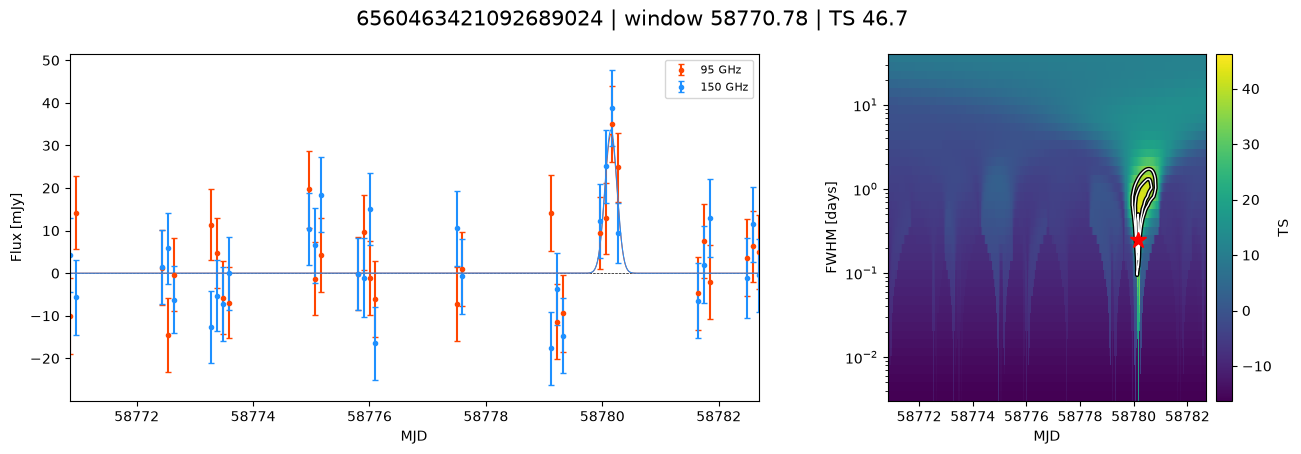

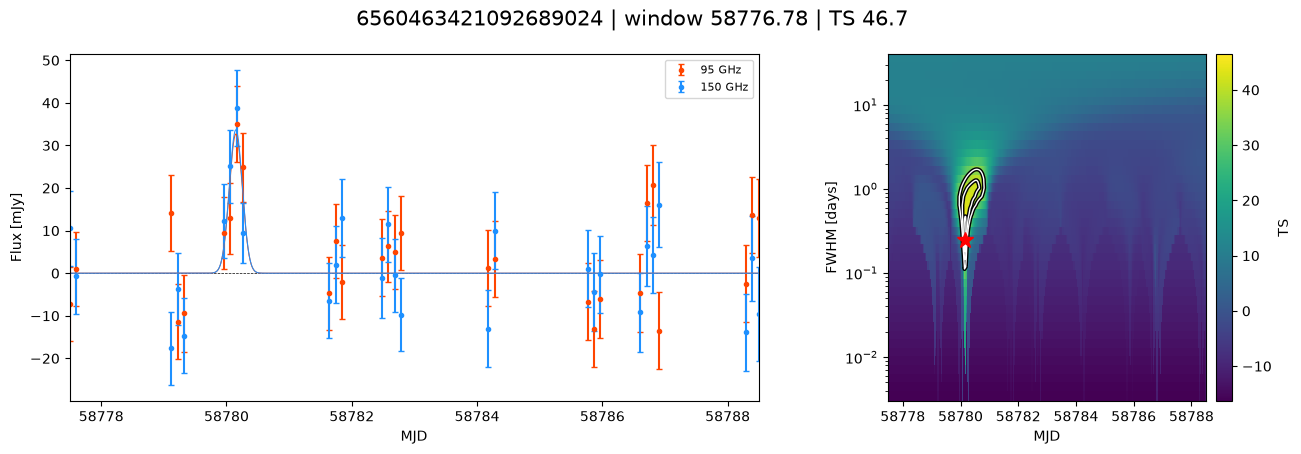

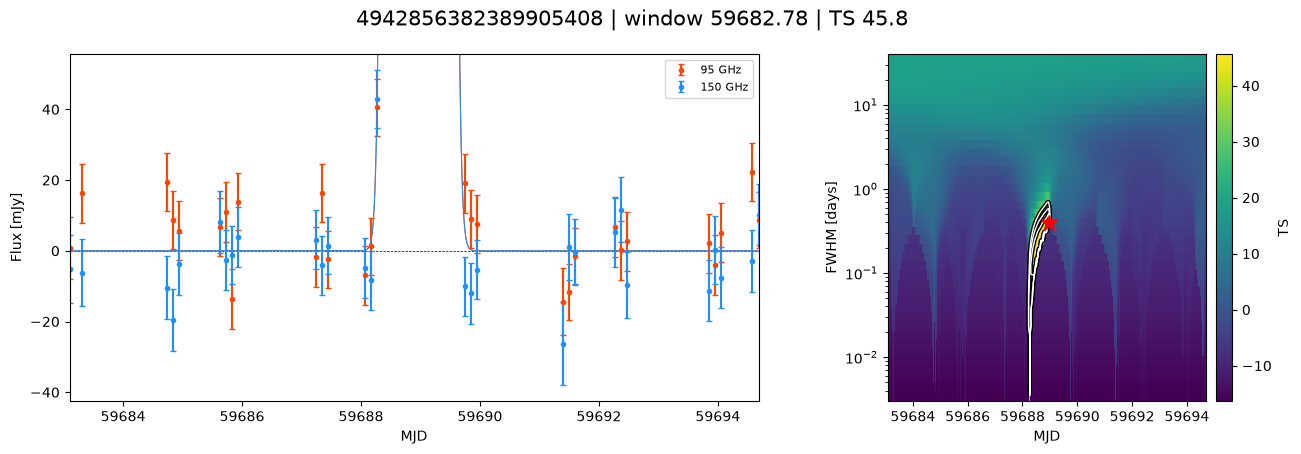

In [26]:
# individually check on the ambiguous windows
ambiguous = null_fits.filter(pl.col('ambiguous')).sort('ts', descending=True)
print(ambiguous.select('gaia_id', 'window_start', 'ts', 'fwhm_d',
                       'snr_amp_95', 'snr_amp_150', 'peak_snr', 'n_3sigma_both'))

for row in ambiguous.iter_rows(named=True):
    time_arr, flux_arr, err_arr, t_ref = spt3g.format_data_fits(
        lightcurves, row['gaia_id'], row['window_start']
    )
    fit = tsf.ts_fit(time_arr, flux_arr, err_arr)
    pltfun.plot_fit(time_arr, flux_arr, err_arr, t_ref, fit,
                    title=f"{row['gaia_id']} | window {row['window_start']:.2f} | TS {row['ts']:.1f}")
    plt.show()

In [27]:
# the 3 ambiguous windows (noise? real flare?) are excluded from training
negatives = null_fits.filter(~pl.col('ambiguous'))   # training negatives and injection hosts
print(f"{negatives.height} negatives, {ambiguous.height} ambiguous held out")

10650 negatives, 3 ambiguous held out


### injection test

In [45]:
alpha_pool = catalog['spectral_index_95_150'].to_numpy()

def run_injections():
    injections = dataset.draw_injections(negatives.select('gaia_id', 'window_start'), n_injections=20000,
                                         alpha_pool=alpha_pool, seed=100)
    return dataset.fit_injections(injections, lightcurves)

inj_fits = load_or_run(f"{data_dir}/inj_fits.parquet", run_injections)
inj_fits.sample(10)

inj_id,gaia_id,window_start,inj_t0_rel_d,inj_fwhm_d,inj_snr_peak,inj_alpha,inj_amp_95,inj_amp_150,inj_max_obs_snr_150,ts,fwhm_d,t0_rel_d,snr_amp_95,snr_amp_150,fwhm_at_bound,n_good,span_d,null_chi2_red,n_3sigma_both,peak_snr
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,i64,f64,f64,i64,f64
13691,"""4900780511935295872""",58998.782153,6.192625,0.02936,1.444234,0.714664,8.233808,11.412136,0.0,4.643792,36.0,1.818125,-1.111042,-1.100978,true,11,8.516968,0.896325,0,0.58485
5960,"""4708842443566593536""",59418.782153,0.878946,0.03223,18.119359,1.14145,70.073609,118.026966,0.000013,2.443055,36.0,11.533681,-0.486534,-0.095473,true,15,10.62191,0.706037,0,1.178376
6702,"""6463546350186454144""",58584.782153,3.503485,0.97212,2.153321,0.175511,16.772578,18.172536,2.072609,13.614163,1.387672,3.895423,3.858312,1.744177,false,17,9.955694,1.808807,0,3.060515
13501,"""4708842443566593536""",59718.782153,5.290475,0.124049,1.233577,-0.139149,8.686481,8.151569,0.995742,3.987831,36.0,0.968935,-0.993749,0.896142,true,15,10.977928,1.290831,0,2.151576
1104,"""4979859106192681344""",58782.782153,2.414974,0.303453,9.528527,-0.061711,89.81063,87.314481,0.000108,3.037137,36.0,10.832894,0.533712,-0.745026,true,25,10.830058,0.638441,0,1.441257
19656,"""6567445491726233216""",59718.782153,0.751344,1.806867,2.030582,1.297957,9.764717,17.665761,1.418265,3.142563,36.0,10.745255,-0.538193,0.809744,true,25,10.680475,0.836561,0,1.560572
15803,"""6478107251392112640""",59754.782153,7.196597,0.094448,23.829585,-0.0012,192.390333,192.28491,5.7918e-7,3.578217,36.0,11.072025,-0.932653,-0.714948,true,23,9.402836,0.636395,0,1.266358
6803,"""6481430353489019776""",59724.782153,4.925102,3.093911,14.660592,-0.320654,163.089577,140.8701,14.365193,1878.015517,3.118056,4.857114,34.315319,26.517349,false,27,10.891377,35.87281,8,23.854525
6879,"""6495448989302214784""",59730.782153,8.769456,2.175158,55.155209,0.535145,322.555462,411.869714,52.938755,12423.239894,2.160564,8.804983,69.636167,87.048683,false,16,9.253727,388.844635,3,66.564101


In [30]:
# integrity checks on injected flares
inj_fits.select((pl.col('inj_max_obs_snr_150') >= 1).mean().alias('observable_frac'))

observable_frac
f64
0.54165


In [31]:
# completeness of the pipeline rules (all cuts, TS > 45) by observed SNR. the (-inf, 0] bin is
# injections with no signal at all in any observation (short flares between scans)
snr_edges = [0, 1, 3, 5, 7, 10, 20]
inj_fits.with_columns(
    (pipeline_cuts & positive_amps).alias('ts_positive_fwhm_pixel_45_detected'),
    ev.bin_series(inj_fits['inj_max_obs_snr_150'], snr_edges, 'observed_snr_bin'),
).group_by('observed_snr_bin').agg(
    pl.col('ts_positive_fwhm_pixel_45_detected').mean().alias('completeness'),
    pl.len().alias('N'),
).sort('observed_snr_bin')

observed_snr_bin,completeness,N
enum,f64,u32
"""(-inf, 0]""",0.0,4695
"""(0, 1]""",0.0,4472
"""(1, 3]""",0.061324,2870
"""(3, 5]""",0.593773,1349
"""(5, 7]""",0.924855,865
"""(7, 10]""",0.993096,869
"""(10, 20]""",0.995831,1679
"""(20, inf]""",0.99875,3201


In [32]:
# leakage check. injections with almost no visible signal should match the negatives. if features are different between
# the two this could lead to the classifier picking up on this instead of real flare signals

faint_injection_limit = 0.3
faint_injections = inj_fits.filter(pl.col('inj_max_obs_snr_150') < faint_injection_limit)

features_to_compare = [
    'ts', 'fwhm_d', 'snr_amp_95', 'snr_amp_150', 'n_good', 'span_d',
    'null_chi2_red', 'n_3sigma_both', 'peak_snr', 'fwhm_at_bound',
]

comparison_rows = []
for feature in features_to_compare:
    negative_values = negatives[feature].cast(pl.Float64).to_numpy()
    faint_injection_values = faint_injections[feature].cast(pl.Float64).to_numpy()
    ks_result = ks_2samp(negative_values, faint_injection_values)
    comparison_rows.append({
        'feature': feature,
        'negatives_median': np.median(negative_values),
        'faint_injections_median': np.median(faint_injection_values),
        'ks_statistic': ks_result.statistic,
        'ks_pvalue': ks_result.pvalue,
    })

leakage_check = pl.DataFrame(comparison_rows)
print(f"{negatives.height} negatives vs {faint_injections.height} faint injections")
leakage_check

10650 negatives vs 8135 faint injections


feature,negatives_median,faint_injections_median,ks_statistic,ks_pvalue
str,f64,f64,f64,f64
"""ts""",4.326839,4.257342,0.017018,0.136699
"""fwhm_d""",36.0,36.0,0.015748,0.200687
"""snr_amp_95""",-0.105762,-0.095535,0.015076,0.242899
"""snr_amp_150""",-0.118139,-0.121207,0.005535,0.998806
"""n_good""",19.0,18.0,0.065534,1.1537e-17
"""span_d""",10.335475,10.160556,0.066846,2.3152e-18
"""null_chi2_red""",0.989873,0.988984,0.01213,0.502146
"""n_3sigma_both""",0.0,0.0,0.000162,1.0
"""peak_snr""",1.805812,1.787595,0.020215,0.04551


In [33]:
# now we'll combine the two to use going forward
negatives_labelled = (negatives.drop('ambiguous')
                      .with_columns(pl.lit(0).alias('label'), pl.lit('quiescent').alias('source')))
positives_labelled = (inj_fits.filter(pl.col('inj_max_obs_snr_150') >= 1)
                      .with_columns(pl.lit(1).alias('label'), pl.lit('injection').alias('source')))
dataset_df = pl.concat([negatives_labelled, positives_labelled], how='diagonal')
dataset_df.write_parquet(f"{data_dir}/dataset.parquet")
print(dataset_df.group_by('label').agg(pl.len().alias('N')).sort('label'))

shape: (2, 2)
┌───────┬───────┐
│ label ┆ N     │
│ ---   ┆ ---   │
│ i32   ┆ u32   │
╞═══════╪═══════╡
│ 0     ┆ 10650 │
│ 1     ┆ 10833 │
└───────┴───────┘


## phase 3 models:

the goal here is to give every window in dataset.parquet a score from each model, where every score comes from a model
that never saw that window's star in training.

In [34]:
# assign folds by star (we're assuming each star's light curve has some unique inherent properties: map edge noise, fraction of focal plane passing over, etc.)

labels = dataset_df['label'].to_numpy()
star_ids = dataset_df['gaia_id'].to_numpy()

# cross-validation: split data into 5 parts, each taking a turn as the test set while a model trains on the other 4
n_folds = 5
fold_splitter = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=100)
fold_of_window = np.full(dataset_df.height, -1)
for fold, (_, test_index) in enumerate(fold_splitter.split(np.zeros(len(labels)), labels, groups=star_ids)):
    fold_of_window[test_index] = fold

fold_of_star = dict(zip(star_ids, fold_of_window)) # used later to score windows outside the dataset
dataset_df = dataset_df.with_columns(pl.Series('fold', fold_of_window))
print(dataset_df.group_by('fold').agg(pl.len().alias('N'), pl.col('label').mean().alias('positive_fraction'),
                                      pl.col('gaia_id').n_unique().alias('N_stars')).sort('fold'))

shape: (5, 4)
┌──────┬──────┬───────────────────┬─────────┐
│ fold ┆ N    ┆ positive_fraction ┆ N_stars │
│ ---  ┆ ---  ┆ ---               ┆ ---     │
│ i64  ┆ u32  ┆ f64               ┆ u32     │
╞══════╪══════╪═══════════════════╪═════════╡
│ 0    ┆ 4215 ┆ 0.502966          ┆ 13      │
│ 1    ┆ 4233 ┆ 0.502953          ┆ 13      │
│ 2    ┆ 4481 ┆ 0.49788           ┆ 14      │
│ 3    ┆ 4327 ┆ 0.507049          ┆ 13      │
│ 4    ┆ 4227 ┆ 0.510764          ┆ 13      │
└──────┴──────┴───────────────────┴─────────┘


In [36]:
# n_good and span_d (leakage check above) have a possibly concerning KS, but they are descriptive of the observation cadence and nothing
# inherent in a potential flare itself. we'll drop them from classifier features.

classifier_features = [
    'ts', 'fwhm_d', 'snr_amp_95', 'snr_amp_150', 'fwhm_at_bound',
    'null_chi2_red', 'n_3sigma_both', 'peak_snr',
]

# logistic regression is sensitive to TS's huge range, so use log TS
# clip negative TS if any occur due to a bad fit + width penalty. this doesn't actually
# happen in our data but we'll put this here just to be explicit
log_ts = (pl.col('ts').clip(lower_bound=0) + 1).log().alias('log_ts')
dataset_df = dataset_df.with_columns(log_ts)
logistic_features = ['log_ts' if f == 'ts' else f for f in classifier_features]
features_without_ts = [f for f in classifier_features if f != 'ts']

models = {
    'logistic': (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                 logistic_features),
    'gbm': (lambda: HistGradientBoostingClassifier(random_state=100), classifier_features),
    'gbm_no_ts': (lambda: HistGradientBoostingClassifier(random_state=100), features_without_ts),
}

def score_with_fold_models(windows):
    """Scores windows outside the dataset with each model, using the fold model that never saw the window's star."""
    window_fold = np.array([fold_of_star[g] for g in windows['gaia_id']])
    for name, (build_model, features) in models.items():
        feature_matrix = windows.select(features).cast(pl.Float64).to_numpy()
        window_score = np.full(windows.height, np.nan)
        for fold in range(n_folds):
            in_fold = window_fold == fold
            if in_fold.any():
                window_score[in_fold] = fitted_models[name][fold].predict_proba(feature_matrix[in_fold])[:, 1]
        windows = windows.with_columns(pl.Series(f"{name}_score", window_score))
    return windows

In [37]:
# feature matrix for each model, built once (rows = windows, columns = that model's features)
feature_matrices = {name: dataset_df.select(features).cast(pl.Float64).to_numpy()
                    for name, (build_model, features) in models.items()}

out_of_fold_scores = {name: np.full(dataset_df.height, np.nan) for name in models}
fitted_models = {name: [] for name in models} # one per fold, for scoring windows outside the dataset in phase 4

for fold in range(n_folds):
    is_test = fold_of_window == fold
    for name, (build_model, features) in models.items():
        feature_matrix = feature_matrices[name]
        model = build_model().fit(feature_matrix[~is_test], labels[~is_test])
        out_of_fold_scores[name][is_test] = model.predict_proba(feature_matrix[is_test])[:, 1]
        fitted_models[name].append(model)
        fold_auc = roc_auc_score(labels[is_test], out_of_fold_scores[name][is_test])
        print(f"fold {fold} {name:10s} AUC {fold_auc:.4f}")

fold 0 logistic   AUC 0.9749
fold 0 gbm        AUC 0.9760
fold 0 gbm_no_ts  AUC 0.9752
fold 1 logistic   AUC 0.9742
fold 1 gbm        AUC 0.9749
fold 1 gbm_no_ts  AUC 0.9760
fold 2 logistic   AUC 0.9720
fold 2 gbm        AUC 0.9754
fold 2 gbm_no_ts  AUC 0.9752
fold 3 logistic   AUC 0.9722
fold 3 gbm        AUC 0.9740
fold 3 gbm_no_ts  AUC 0.9747
fold 4 logistic   AUC 0.9698
fold 4 gbm        AUC 0.9705
fold 4 gbm_no_ts  AUC 0.9693


In [38]:
all(np.isfinite(s).all() for s in out_of_fold_scores.values())

True

In [41]:
# TS as a detection score: TS where a window passes the cuts, -1e9 otherwise, for three versions of the cuts
#   ts_positive_fwhm_pixel: pipeline cuts (positive amplitudes, FWHM < 10 d, pixel significance cut)
#   ts_positive_fwhm:       no pixel significance cut
#   ts_positive:            positive amplitudes only
ts_methods = ['ts_positive_fwhm_pixel_score', 'ts_positive_fwhm_score', 'ts_positive_score']
model_methods = [f"{name}_score" for name in models]
methods = ts_methods + model_methods

# scored: every window's features, TS scores and out-of-fold model scores, used for all of phase 4
scored = ev.ts_scores(dataset_df).with_columns(
    *[pl.Series(f"{name}_score", s) for name, s in out_of_fold_scores.items()])

scores_df = scored.select('gaia_id', 'window_start', 'inj_id', 'label', 'source', 'fold',
                          'inj_max_obs_snr_150', 'inj_fwhm_d', 'inj_alpha', *methods)
scores_df.write_parquet(f"{data_dir}/scores.parquet")
scores_df.sample(10)

gaia_id,window_start,inj_id,label,source,fold,inj_max_obs_snr_150,inj_fwhm_d,inj_alpha,ts_positive_fwhm_pixel_score,ts_positive_fwhm_score,ts_positive_score,logistic_score,gbm_score,gbm_no_ts_score
str,f64,i64,i32,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""4727935836644070656""",59472.782153,null,0,"""quiescent""",3,null,null,null,-1.0000e9,-1.0000e9,-1.0000e9,0.025372,0.023096,0.019843
"""4708842443566593536""",58758.782153,null,0,"""quiescent""",1,null,null,null,-1.0000e9,-1.0000e9,-1.0000e9,0.040659,0.016194,0.016426
"""4918091463521598592""",59358.782153,null,0,"""quiescent""",2,null,null,null,-1.0000e9,-1.0000e9,-1.0000e9,0.029851,0.0528,0.048884
"""4933323685296675584""",58602.782153,null,0,"""quiescent""",3,null,null,null,-1.0000e9,-1.0000e9,-1.0000e9,0.073498,0.054221,0.054682
"""6470742481994348416""",59676.782153,13707,1,"""injection""",4,40.166228,4.689873,0.203006,11985.747261,11985.747261,11985.747261,1.0,0.99907,0.999385
"""4905813212878537216""",58938.782153,110,1,"""injection""",1,91.297882,9.585739,1.438113,59908.679119,59908.679119,59908.679119,1.0,0.999698,0.999067
"""4910314961376339584""",58734.782153,null,0,"""quiescent""",2,null,null,null,-1.0000e9,-1.0000e9,2.292173,0.026714,0.027744,0.016845
"""4920330653311504256""",59898.782153,null,0,"""quiescent""",3,null,null,null,-1.0000e9,-1.0000e9,-1.0000e9,0.036386,0.144196,0.075949
"""6524079447458513536""",59478.782153,null,0,"""quiescent""",3,null,null,null,-1.0000e9,-1.0000e9,-1.0000e9,0.061187,0.015496,0.018998


In [47]:
# every window scored
print(scored.select([pl.col(c).is_nan().sum() for c in model_methods]))

# the TS baseline at 45 on this dataset
print(scored.group_by('label').agg(
    (pl.col('ts_positive_fwhm_pixel_score') > 45).sum().alias('N_ts_positive_fwhm_pixel_45_detected'),
    pl.len().alias('N')).sort('label'))

# how the model scores are distributed for each class
for c in model_methods:
    print(c, scored.group_by('label').agg(
        pl.col(c).quantile(0.5).alias('median'),
        pl.col(c).quantile(0.99).alias('p99'),
        pl.col(c).max().alias('max')).sort('label'))

shape: (1, 3)
┌────────────────┬───────────┬─────────────────┐
│ logistic_score ┆ gbm_score ┆ gbm_no_ts_score │
│ ---            ┆ ---       ┆ ---             │
│ u32            ┆ u32       ┆ u32             │
╞════════════════╪═══════════╪═════════════════╡
│ 0              ┆ 0         ┆ 0               │
└────────────────┴───────────┴─────────────────┘
shape: (2, 3)
┌───────┬─────────────────────────────────┬───────┐
│ label ┆ N_ts_positive_fwhm_pixel_45_de… ┆ N     │
│ ---   ┆ ---                             ┆ ---   │
│ i32   ┆ u32                             ┆ u32   │
╞═══════╪═════════════════════════════════╪═══════╡
│ 0     ┆ 0                               ┆ 10650 │
│ 1     ┆ 7509                            ┆ 10833 │
└───────┴─────────────────────────────────┴───────┘
logistic_score shape: (2, 4)
┌───────┬──────────┬──────────┬──────────┐
│ label ┆ median   ┆ p99      ┆ max      │
│ ---   ┆ ---      ┆ ---      ┆ ---      │
│ i32   ┆ f64      ┆ f64      ┆ f64      │
╞═══════╪═══

## phase 4: evaluation

In [55]:
# recall at zero fp against the raw quiescent windows, and who the top negatives are
for c in methods:
    highest_negative = scored.filter(pl.col('label') == 0)[c].max()
    recall_zero_fp = scored.filter(pl.col('label') == 1).select((pl.col(c) > highest_negative).mean()).item()
    print(f"{c:30s}| highest negative: {highest_negative:8.4f} | recall at 0 FP: {recall_zero_fp:.3f}")

top_negatives = scored.filter(pl.col('label') == 0).sort('gbm_score', descending=True).head(10)
top_negatives.select('gaia_id', 'window_start', 'gbm_score', 'ts_positive_fwhm_pixel_score', 'ts', 'fwhm_d',
                     'snr_amp_95', 'snr_amp_150', 'peak_snr', 'n_3sigma_both')

ts_positive_fwhm_pixel_score  | highest negative:  44.6338 | recall at 0 FP: 0.694
ts_positive_fwhm_score        | highest negative:  73.0339 | recall at 0 FP: 0.678
ts_positive_score             | highest negative:  73.0339 | recall at 0 FP: 0.687
logistic_score                | highest negative:   0.9967 | recall at 0 FP: 0.674
gbm_score                     | highest negative:   0.9993 | recall at 0 FP: 0.393
gbm_no_ts_score               | highest negative:   0.9993 | recall at 0 FP: 0.380


gaia_id,window_start,gbm_score,ts_positive_fwhm_pixel_score,ts,fwhm_d,snr_amp_95,snr_amp_150,peak_snr,n_3sigma_both
str,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""4918091463521598592""",59766.782153,0.999337,-1.0000e9,73.033869,0.212968,3.448193,8.319067,6.167384,0
"""6471134835842209792""",59334.782153,0.997535,-1.0000e9,62.356452,0.773025,6.901819,4.495114,6.348773,0
"""6471134835842209792""",59340.782153,0.997535,-1.0000e9,62.356452,0.772994,6.901856,4.495066,6.348773,0
"""4918091463521598592""",59772.782153,0.997388,-1.0000e9,73.033869,0.212968,3.448187,8.31907,6.167384,0
"""4708842443566593536""",59154.782153,0.995926,-1.0000e9,33.921916,7.501196,4.345702,3.997059,3.365061,0
"""4708842443566593536""",59160.782153,0.995043,-1.0000e9,33.51829,9.27988,4.367879,3.867045,3.365061,0
"""4726387007013852672""",58572.782153,0.994111,32.280879,32.280879,0.684484,2.814522,5.485193,5.250176,1
"""6456528236185330816""",59898.782153,0.992771,44.633775,44.633775,2.741815,5.230022,4.498135,5.672044,1
"""4946915641880235904""",59394.782153,0.991248,-1.0000e9,36.252803,0.145499,2.86621,6.07146,6.14128,0


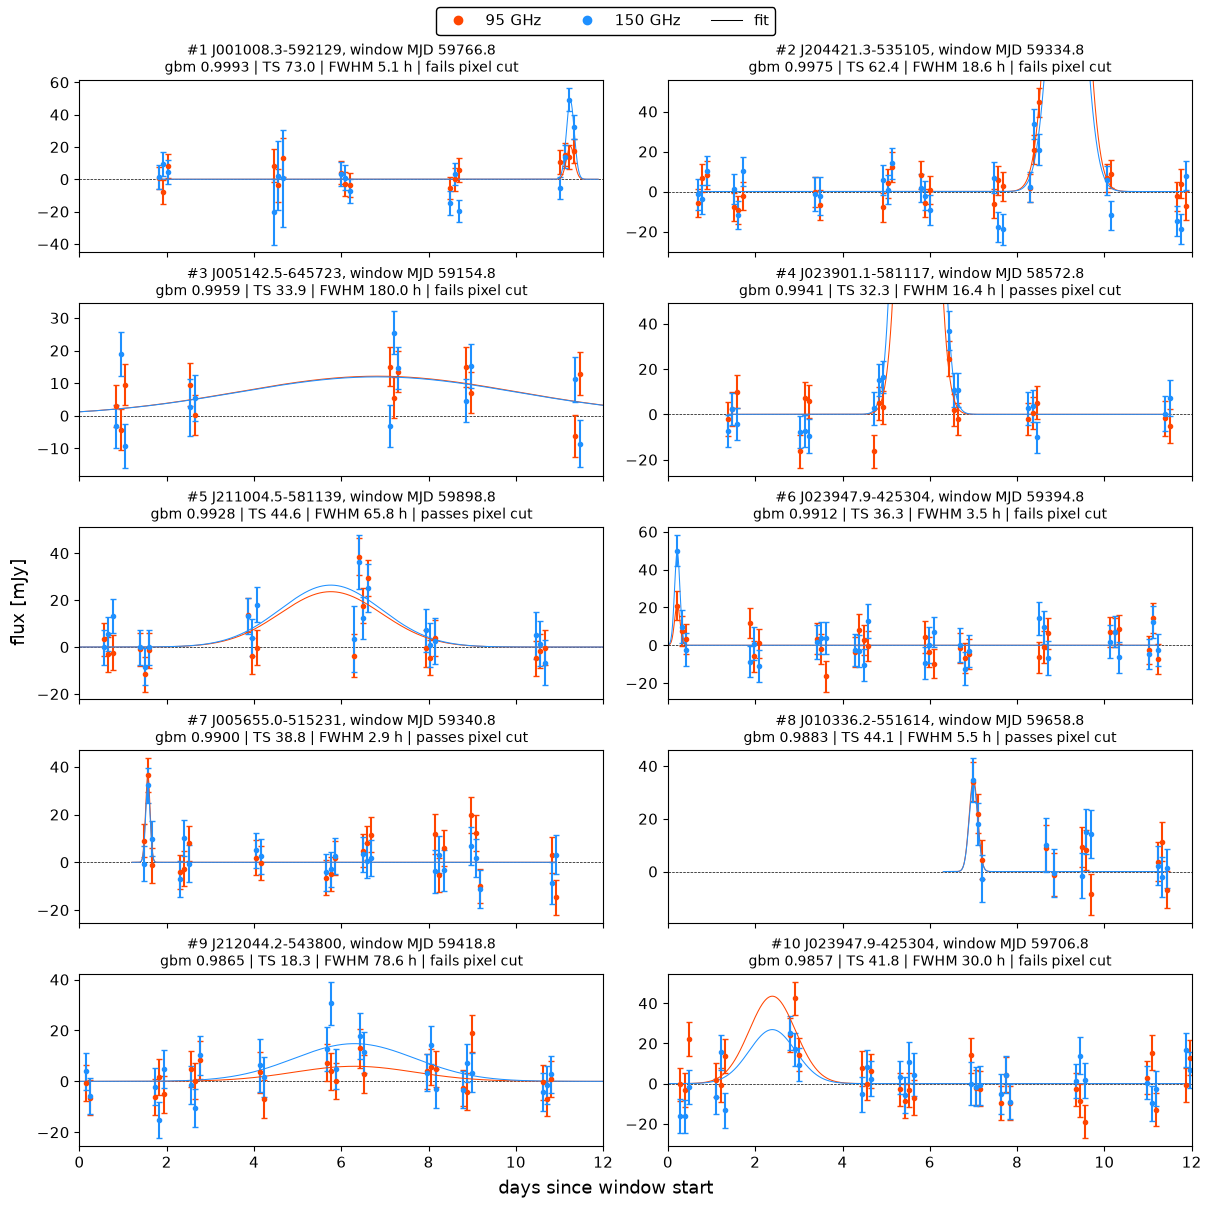

In [125]:
# the ten highest-scoring quiescent windows by gbm score, one per event: a flare often shows up in two overlapping
# windows, so windows overlapping one already shown on the same star are skipped. several look like real flares,
# which is why raw negatives make a poor false-positive reference
spt_names = {gaia_id: spt_id.replace('SPT-SV ', '')
             for gaia_id, spt_id in lightcurves.select('gaia_id', 'spt_id').unique().iter_rows()}

top_events = []
for row in scored.filter(pl.col('label') == 0).sort('gbm_score', descending=True).iter_rows(named=True):
    if any(row['gaia_id'] == shown['gaia_id'] and abs(row['window_start'] - shown['window_start']) < 12
           for shown in top_events):
        continue
    top_events.append(row)
    if len(top_events) == 10:
        break

with plt.rc_context({'font.size': 11}):
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), layout='constrained', sharex=True)
    for rank, (ax, row) in enumerate(zip(axes.flat, top_events), start=1):
        time_arr, flux_arr, err_arr, t_ref = spt3g.format_data_fits(lightcurves, row['gaia_id'], row['window_start'])
        fit = tsf.ts_fit(time_arr, flux_arr, err_arr)
        # t_ref = 0 puts x in days since the window start, the same for every panel
        pltfun.plot_lightcurve_fit(ax, time_arr, flux_arr, err_arr, 0, fit)
        pixel_cut = 'passes' if row['n_3sigma_both'] >= 1 else 'fails'
        ax.set_title(f"#{rank} {spt_names[row['gaia_id']]}, window MJD {row['window_start']:.1f}\n"
                     f"gbm {row['gbm_score']:.4f} | TS {fit[0]:.1f} | FWHM {fit[2] * 24:.1f} h | {pixel_cut} pixel cut",
                     fontsize=10)
    axes[0, 0].set_xlim(0, 12)
    legend_handles = [Line2D([], [], color=color, marker='o', ls='none', label=band)
                      for band, color in pltfun.BAND_COLORS.items()]
    legend_handles.append(Line2D([], [], color='k', lw=0.75, label='fit'))
    fig.legend(handles=legend_handles, loc='outside upper center', ncols=3, edgecolor='k', framealpha=1)
    fig.supxlabel('days since window start')
    fig.supylabel('flux [mJy]')
    plt.savefig(f"{image_dir}/evaluation/top_negatives.png", dpi=150, bbox_inches='tight')

N = 105,255; SNR std 1.010 (95), 1.005 (150)
2 sigma: expected 54.5 each; {'both +': 121, 'both $-$': 57, '95 + 150 $-$': 51, '95 $-$ 150 +': 54}
3 sigma: expected 0.2 each; {'both +': 17, 'both $-$': 1, '95 + 150 $-$': 0, '95 $-$ 150 +': 0}


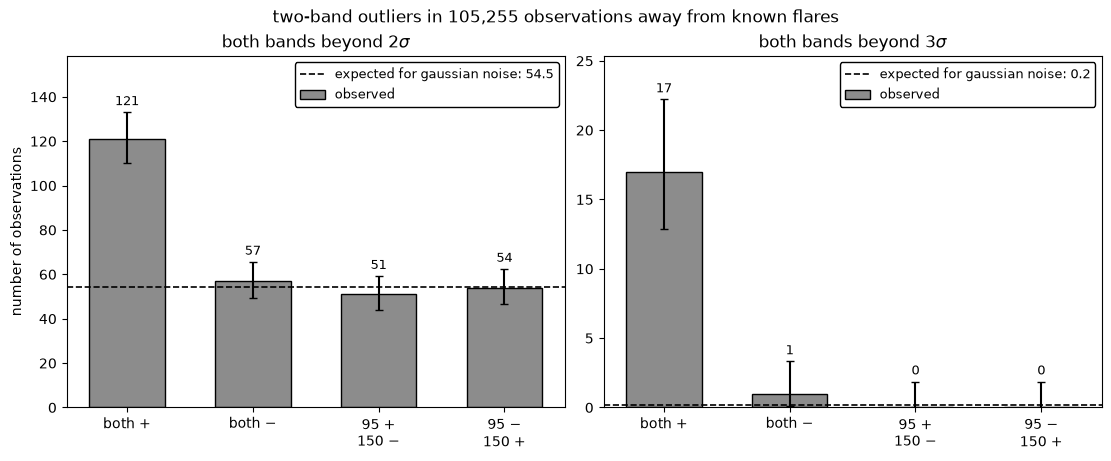

In [111]:
# is the noise sign-symmetric? if the two bands' noise is white and independent, an observation beyond k sigma in
# both bands is equally likely for all four sign combinations. residual atmosphere would add same-sign outliers of
# both signs; real flares add only positive ones. observations within 6 d of a known flare are left out
lc_gaia = lightcurves['gaia_id'].to_numpy()
lc_mjd = lightcurves['mjd'].to_numpy()
near_flare = np.zeros(lightcurves.height, dtype=bool)
for gaia_id, flare_mjds in known_flares.group_by('dr3_source_id').agg('mjd').iter_rows():
    on_star = lc_gaia == gaia_id
    near_flare[on_star] = (np.abs(lc_mjd[on_star, None] - np.array(flare_mjds)[None, :]) < 6).any(axis=1)

quiet_obs = (lightcurves.filter(~near_flare)
             .filter(pl.col('err_95').is_finite() & (pl.col('err_95') > 0)
                     & pl.col('err_150').is_finite() & (pl.col('err_150') > 0))
             .select((pl.col('flux_95') / pl.col('err_95')).alias('snr_95'),
                     (pl.col('flux_150') / pl.col('err_150')).alias('snr_150')))
snr_95, snr_150 = quiet_obs['snr_95'].to_numpy(), quiet_obs['snr_150'].to_numpy()
print(f"N = {quiet_obs.height:,}; SNR std {snr_95.std():.3f} (95), {snr_150.std():.3f} (150)")

sign_combinations = {
    'both +': (1, 1),
    'both $-$': (-1, -1),
    '95 +\n150 $-$': (1, -1),
    '95 $-$\n150 +': (-1, 1),
}
sigma_levels = [2, 3]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for ax, k in zip(axes, sigma_levels):
    # expected count per sign combination for independent gaussian noise
    expected = quiet_obs.height * norm.sf(k) ** 2
    counts = np.array([((sign_95 * snr_95 > k) & (sign_150 * snr_150 > k)).sum()
                       for sign_95, sign_150 in sign_combinations.values()])
    print(f"{k} sigma: expected {expected:.1f} each;",
          dict(zip([label.replace('\n', ' ') for label in sign_combinations], counts.tolist())))
    x = np.arange(len(sign_combinations))
    upper_error = np.sqrt(counts + 0.75) + 1 # Gehrels (1986) 1-sigma Poisson upper error
    lower_error = np.sqrt(np.maximum(counts - 0.25, 0)) # lower error, 0 at a count of 0
    bars = ax.bar(x, counts, width=0.6, color='0.55', edgecolor='k', yerr=[lower_error, upper_error], capsize=3,
              label='observed')                                       
    ax.bar_label(bars, padding=3, fontsize=9)
    ax.axhline(expected, color='k', ls='--', lw=1.2, label=f"expected for gaussian noise: {expected:.1f}")
    ax.set_xticks(x, labels=list(sign_combinations))
    ax.set_title(f"both bands beyond {k}$\\sigma$")
    ax.set_ylim(0, max(counts.max() + np.sqrt(counts.max()), expected) * 1.2)
    ax.legend(loc='upper right', fontsize=9, edgecolor='k', framealpha=1)
axes[0].set_ylabel('number of observations')
fig.suptitle(f"two-band outliers in {quiet_obs.height:,} observations away from known flares")
plt.savefig(f"{image_dir}/evaluation/interband_sign_test.png", dpi=150, bbox_inches='tight')

### mirrored negatives

In [58]:
# several of the top negatives look like real flares, so they're a bad false-positive reference.
# flip each quiescent window's flux: real flares become dips, noise stays noise
mirrored_rows = []
for row in tqdm(negatives.iter_rows(named=True), total=negatives.height):
    time_arr, flux_arr, err_arr, t_ref = spt3g.format_data_fits(
        lightcurves, row['gaia_id'], row['window_start'])
    # TS, t0 and FWHM don't change sign; amplitudes flip (amp_errs = 1 keeps snr_amp_* as SNRs)
    mirrored_fit = (row['ts'], row['t0_rel_d'], row['fwhm_d'],
                    np.array([-row['snr_amp_95'], -row['snr_amp_150']]), np.ones(2), None)
    mirrored_rows.append({'gaia_id': row['gaia_id'], 'window_start': row['window_start'],
                          **dataset.window_features(time_arr, -flux_arr, err_arr, mirrored_fit)})
mirrored = pl.DataFrame(mirrored_rows).with_columns(log_ts)

# score each mirrored window with the model that never saw its star
mirrored = ev.ts_scores(score_with_fold_models(mirrored))
mirrored.write_parquet(f"{data_dir}/mirrored_negatives.parquet")

# recall when each method is allowed zero false positives on pure noise
noise_threshold = {m: mirrored[m].max() for m in methods}
positives = scored.filter(pl.col('label') == 1)
for m in methods:
    recall = positives.select((pl.col(m) > noise_threshold[m]).mean()).item()
    print(f"{m:30s}| highest mirrored negative: {noise_threshold[m]:8.4f} | recall at 0 noise FP: {recall:.3f}")

  0%|          | 0/10650 [00:00<?, ?it/s]

ts_positive_fwhm_pixel_score  | highest mirrored negative:  20.8835 | recall at 0 noise FP: 0.715
ts_positive_fwhm_score        | highest mirrored negative:  27.1947 | recall at 0 noise FP: 0.787
ts_positive_score             | highest mirrored negative:  29.1214 | recall at 0 noise FP: 0.796
logistic_score                | highest mirrored negative:   0.9207 | recall at 0 noise FP: 0.808
gbm_score                     | highest mirrored negative:   0.9800 | recall at 0 noise FP: 0.787
gbm_no_ts_score               | highest mirrored negative:   0.9788 | recall at 0 noise FP: 0.795


### real flares

In [59]:
# now that we've scored the models on mirrored negatives and tested recall on injected flares, time to test on the real flares

# 110 validated catalog events (+ the one with its detection obs missing) + Guns, Tandoi et al. (2026) flare 5
real_events = pl.concat([
    catalog.select(pl.col('dr3_source_id').alias('gaia_id'), 'spt_id', 'mjd', pl.lit('catalog').alias('origin')),
    pl.DataFrame({'gaia_id': ['6456528236185330816'], 'spt_id': ['Guns26 flare 5'],
                  'mjd': [59083.43], 'origin': ['guns2026']}),
])
known_mjds = dict(real_events.group_by('gaia_id').agg('mjd').iter_rows())

event_rows = []
for event in tqdm(real_events.iter_rows(named=True), total=real_events.height):
    other_mjds = [m for m in known_mjds[event['gaia_id']] if m != event['mjd']]
    for t_start in spt3g.window_starts(event['mjd'], fixed_anchor):
        time_arr, flux_arr, err_arr, t_ref = spt3g.format_data_fits(
            lightcurves, event['gaia_id'], t_start, mask_mjds=other_mjds)
        if np.isfinite(err_arr).all(axis=0).sum() < 6:
            continue
        fit = tsf.ts_fit(time_arr, flux_arr, err_arr)
        event_rows.append({**event, 'window_start': t_start,
                           **dataset.window_features(time_arr, flux_arr, err_arr, fit)})

# score each window with its star's out-of-fold model
event_windows = ev.ts_scores(score_with_fold_models(pl.DataFrame(event_rows).with_columns(log_ts)))

# per event: best of its windows; detected if above the noise threshold
event_results = (event_windows.group_by('gaia_id', 'spt_id', 'mjd', 'origin')
    .agg([pl.col(m).max() for m in methods])
    .with_columns(*[(pl.col(m) > noise_threshold[m]).alias(m.replace('_score', '_detected')) for m in methods],
                  (pl.col('ts_positive_fwhm_pixel_score') > 45).alias('ts_positive_fwhm_pixel_45_detected')))

print(f"{event_windows.height} event windows")
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(event_results.group_by('origin').agg(
        pl.len().alias('N'), *[pl.col(c).sum() for c in event_results.columns if c.endswith('_detected')]))

  0%|          | 0/112 [00:00<?, ?it/s]

223 event windows
shape: (2, 9)
┌──────────┬─────┬─────────────────────────────────┬───────────────────────────┬──────────────────────┬───────────────────┬──────────────┬────────────────────┬─────────────────────────────────┐
│ origin   ┆ N   ┆ ts_positive_fwhm_pixel_detecte… ┆ ts_positive_fwhm_detected ┆ ts_positive_detected ┆ logistic_detected ┆ gbm_detected ┆ gbm_no_ts_detected ┆ ts_positive_fwhm_pixel_45_dete… │
│ ---      ┆ --- ┆ ---                             ┆ ---                       ┆ ---                  ┆ ---               ┆ ---          ┆ ---                ┆ ---                             │
│ str      ┆ u32 ┆ u32                             ┆ u32                       ┆ u32                  ┆ u32               ┆ u32          ┆ u32                ┆ u32                             │
╞══════════╪═════╪═════════════════════════════════╪═══════════════════════════╪══════════════════════╪═══════════════════╪══════════════╪════════════════════╪═════════════════════════════════

### what about the real flares that GBM missed?

In [60]:
missed_by_gbm = (event_results
    .filter(pl.col('origin') == 'catalog', pl.col('ts_positive_fwhm_pixel_45_detected'),
            ~pl.col('gbm_detected') | ~pl.col('gbm_no_ts_detected'))
    .join(catalog.select(pl.col('dr3_source_id').alias('gaia_id'), 'mjd', 'ts_published'),
          on=['gaia_id', 'mjd'])
    .sort('ts_published'))
missed_by_gbm.select('spt_id', 'mjd', 'ts_published', 'ts_positive_fwhm_pixel_score',
                     'gbm_score', 'gbm_no_ts_score', 'logistic_score')

spt_id,mjd,ts_published,ts_positive_fwhm_pixel_score,gbm_score,gbm_no_ts_score,logistic_score
str,f64,f64,f64,f64,f64,f64
"""SPT-SV J204421.6-535104""",59887.43,49.530379,47.49811,0.977963,0.987668,0.987385
"""SPT-SV J024204.1-535911""",59769.96,49.800195,45.173676,0.883809,0.83671,0.989658
"""SPT-SV J225726.8-564528""",58595.56,53.745787,47.983985,0.94928,0.900995,0.978348
"""SPT-SV J213023.8-601210""",59778.0,103.799517,74.145562,0.979501,0.991813,0.998503


In [61]:
missed_windows = event_windows.join(missed_by_gbm.select('gaia_id', 'mjd'), on=['gaia_id', 'mjd'])
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(missed_windows.select('spt_id', 'window_start', 'ts', 'fwhm_d', 'fwhm_at_bound',
                                'snr_amp_95', 'snr_amp_150', 'null_chi2_red', 'n_3sigma_both',
                                'peak_snr', 'gbm_score'))

shape: (8, 11)
┌─────────────────────────┬──────────────┬───────────┬──────────┬───────────────┬────────────┬─────────────┬───────────────┬───────────────┬──────────┬───────────┐
│ spt_id                  ┆ window_start ┆ ts        ┆ fwhm_d   ┆ fwhm_at_bound ┆ snr_amp_95 ┆ snr_amp_150 ┆ null_chi2_red ┆ n_3sigma_both ┆ peak_snr ┆ gbm_score │
│ ---                     ┆ ---          ┆ ---       ┆ ---      ┆ ---           ┆ ---        ┆ ---         ┆ ---           ┆ ---           ┆ ---      ┆ ---       │
│ str                     ┆ f64          ┆ f64       ┆ f64      ┆ bool          ┆ f64        ┆ f64         ┆ f64           ┆ i64           ┆ f64      ┆ f64       │
╞═════════════════════════╪══════════════╪═══════════╪══════════╪═══════════════╪════════════╪═════════════╪═══════════════╪═══════════════╪══════════╪═══════════╡
│ SPT-SV J225726.8-564528 ┆ 58584.782153 ┆ 46.563612 ┆ 0.165545 ┆ false         ┆ 5.779797   ┆ 4.660943    ┆ 2.121833      ┆ 2             ┆ 5.802264 ┆ 0.947633  │
│

#### spectral index bias?

In [62]:
# near-threshold injections (fitted TS 44-56, fitted FWHM < 1 d) by their true injected spectral index
near_threshold_injections = (positives
    .filter(pl.col('ts').is_between(44, 56), pl.col('fwhm_d') < 1)
    .with_columns(pl.when(pl.col('inj_alpha') < -0.5).then(pl.lit('falling'))
                    .when(pl.col('inj_alpha') > 0.5).then(pl.lit('rising'))
                    .otherwise(pl.lit('flat')).alias('true_spectrum')))
print(near_threshold_injections.group_by('true_spectrum').agg(
    pl.len().alias('N'),
    *[(pl.col(m) > noise_threshold[m]).mean().alias(m.replace('_score', '_detected_frac'))
      for m in ['gbm_score', 'logistic_score']]).sort('true_spectrum'))

shape: (3, 4)
┌───────────────┬─────┬───────────────────┬────────────────────────┐
│ true_spectrum ┆ N   ┆ gbm_detected_frac ┆ logistic_detected_frac │
│ ---           ┆ --- ┆ ---               ┆ ---                    │
│ str           ┆ u32 ┆ f64               ┆ f64                    │
╞═══════════════╪═════╪═══════════════════╪════════════════════════╡
│ falling       ┆ 13  ┆ 0.384615          ┆ 1.0                    │
│ flat          ┆ 40  ┆ 0.7               ┆ 1.0                    │
│ rising        ┆ 42  ┆ 0.904762          ┆ 1.0                    │
└───────────────┴─────┴───────────────────┴────────────────────────┘


### purity and completeness

In [63]:
n_noise_windows = mirrored.height
n_real_flares = event_results.height
operating_fpr_levels = [0, 1e-4, 1e-3, 1e-2]

rows = []
for method in methods:
    noise_scores = np.sort(mirrored[method].to_numpy())[::-1]
    for fpr in operating_fpr_levels:
        n_allowed = int(round(fpr * n_noise_windows))
        threshold = noise_scores[n_allowed]
        completeness = positives.select((pl.col(method) > threshold).mean()).item()
        real_recall = event_results.select((pl.col(method) > threshold).mean()).item()
        expected_real_detections = real_recall * n_real_flares
        rows.append({
            'method': method.replace('_score', ''),
            'fpr': fpr,
            'threshold': threshold,
            'injection_completeness': completeness,
            'real_event_recall': real_recall,
            'expected_false_alarms': n_allowed,
            'estimated_purity': expected_real_detections / (expected_real_detections + n_allowed),
        })

operating_points = pl.DataFrame(rows)
with pl.Config(tbl_rows=-1):
    print(operating_points)

shape: (24, 7)
┌───────────────┬────────┬───────────┬───────────────┬───────────────┬──────────────┬──────────────┐
│ method        ┆ fpr    ┆ threshold ┆ injection_com ┆ real_event_re ┆ expected_fal ┆ estimated_pu │
│ ---           ┆ ---    ┆ ---       ┆ pleteness     ┆ call          ┆ se_alarms    ┆ rity         │
│ str           ┆ f64    ┆ f64       ┆ ---           ┆ ---           ┆ ---          ┆ ---          │
│               ┆        ┆           ┆ f64           ┆ f64           ┆ i64          ┆ f64          │
╞═══════════════╪════════╪═══════════╪═══════════════╪═══════════════╪══════════════╪══════════════╡
│ ts_positive_f ┆ 0.0    ┆ 20.883481 ┆ 0.715222      ┆ 0.982143      ┆ 0            ┆ 1.0          │
│ whm_pixel     ┆        ┆           ┆               ┆               ┆              ┆              │
│ ts_positive_f ┆ 0.0001 ┆ 16.854217 ┆ 0.717161      ┆ 0.982143      ┆ 1            ┆ 0.990991     │
│ whm_pixel     ┆        ┆           ┆               ┆               ┆      

#### where does the classifier's gain come from? is this a real advantage or does it reflect on a limit of the pipeline?

In [64]:
# overall recall at zero noise false positives, from the pipeline rules down to logistic regression
print(f"{'pipeline rules (TS > 45)':30s} recall {positives.select((pl.col('ts_positive_fwhm_pixel_score') > 45).mean()).item():.3f}")
for m in methods:
    recall = positives.select((pl.col(m) > noise_threshold[m]).mean()).item()
    print(f"{m:30s} noise threshold {noise_threshold[m]:10.4f}  recall {recall:.3f}")

# recall by observed SNR
recall_by_bin = (positives
    .with_columns(ev.bin_series(positives['inj_max_obs_snr_150'], [1, 3, 5, 7, 10, 20], 'observed_snr_bin'))
    .group_by('observed_snr_bin')
    .agg(pl.len().alias('N'),
         (pl.col('ts_positive_fwhm_pixel_score') > 45).mean().alias('ts_positive_fwhm_pixel_45'),
         *[(pl.col(m) > noise_threshold[m]).mean().alias(m.replace('_score', '')) for m in methods])
    .sort('observed_snr_bin'))
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(recall_by_bin)

pipeline rules (TS > 45)       recall 0.693
ts_positive_fwhm_pixel_score   noise threshold    20.8835  recall 0.715
ts_positive_fwhm_score         noise threshold    27.1947  recall 0.787
ts_positive_score              noise threshold    29.1214  recall 0.796
logistic_score                 noise threshold     0.9207  recall 0.808
gbm_score                      noise threshold     0.9800  recall 0.787
gbm_no_ts_score                noise threshold     0.9788  recall 0.795
shape: (6, 9)
┌──────────────────┬──────┬───────────────────────────┬────────────────────────┬──────────────────┬─────────────┬──────────┬──────────┬───────────┐
│ observed_snr_bin ┆ N    ┆ ts_positive_fwhm_pixel_45 ┆ ts_positive_fwhm_pixel ┆ ts_positive_fwhm ┆ ts_positive ┆ logistic ┆ gbm      ┆ gbm_no_ts │
│ ---              ┆ ---  ┆ ---                       ┆ ---                    ┆ ---              ┆ ---         ┆ ---      ┆ ---      ┆ ---       │
│ enum             ┆ u32  ┆ f64                       ┆ f64       

bootstrap new sample populations lots of times, let's figure out whether the logistic regression performance is real or not

In [65]:
# resample whole stars with replacement (positives and their mirrored noise together), same replicates for every method
fpr_levels = (0, 1e-4, 1e-3)
full_recall, boot_recall = ev.bootstrap_recall(positives, mirrored, methods, fpr_levels)

with pl.Config(tbl_rows=-1):
    print(ev.recall_table(full_recall, boot_recall, methods, fpr_levels))
    # paired comparison: logistic minus TS without the pixel significance cut, within each replicate
    print('logistic - ts_positive')
    print(ev.paired_difference(full_recall, boot_recall, methods, 'logistic_score', 'ts_positive_score', fpr_levels))

  0%|          | 0/1000 [00:00<?, ?it/s]

shape: (18, 5)
┌────────┬────────────────────────┬──────────┬──────────┬──────────┐
│ fpr    ┆ method                 ┆ recall   ┆ ci_low   ┆ ci_high  │
│ ---    ┆ ---                    ┆ ---      ┆ ---      ┆ ---      │
│ f64    ┆ str                    ┆ f64      ┆ f64      ┆ f64      │
╞════════╪════════════════════════╪══════════╪══════════╪══════════╡
│ 0.0    ┆ ts_positive_fwhm_pixel ┆ 0.715222 ┆ 0.707498 ┆ 0.725566 │
│ 0.0    ┆ ts_positive_fwhm       ┆ 0.787317 ┆ 0.780462 ┆ 0.835504 │
│ 0.0    ┆ ts_positive            ┆ 0.795532 ┆ 0.788268 ┆ 0.830827 │
│ 0.0    ┆ logistic               ┆ 0.808363 ┆ 0.800831 ┆ 0.857403 │
│ 0.0    ┆ gbm                    ┆ 0.787317 ┆ 0.779609 ┆ 0.814073 │
│ 0.0    ┆ gbm_no_ts              ┆ 0.795255 ┆ 0.788209 ┆ 0.810182 │
│ 0.0001 ┆ ts_positive_fwhm_pixel ┆ 0.717161 ┆ 0.708179 ┆ 0.725922 │
│ 0.0001 ┆ ts_positive_fwhm       ┆ 0.798763 ┆ 0.782853 ┆ 0.838846 │
│ 0.0001 ┆ ts_positive            ┆ 0.800978 ┆ 0.790431 ┆ 0.831688 │
│ 0.0001 ┆ logistic

In [79]:
# observed SNR with both bands combined in quadrature, for the completeness figures. the main injections
# only stored the 150 GHz version, so rebuild each injection's signal from its parameters (no refitting).
# the 150 GHz value is recomputed too, as a check that the rebuild matches what fit_injections() saw
def run_observed_snr():
    return pl.concat([positives.select('inj_id'), dataset.observed_signal_snr(positives, lightcurves)],
                     how='horizontal')

observed_snr_table = load_or_run(f"{data_dir}/inj_observed_snr.parquet", run_observed_snr)
assert (observed_snr_table['inj_id'] == positives['inj_id']).all()
assert np.allclose(observed_snr_table['inj_max_obs_snr_150'], positives['inj_max_obs_snr_150'])
positives = positives.with_columns(observed_snr_table['inj_max_obs_snr_combined'])

  0%|          | 0/10833 [00:00<?, ?it/s]

lowered threshold: TS > 27.19


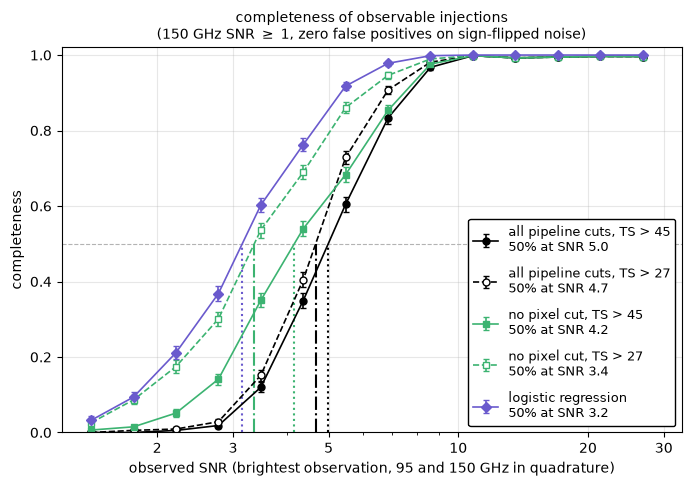

In [102]:
# completeness of the observable injections vs observed SNR: the pipeline cuts with and without the pixel
# significance cut, each at the pipeline's TS > 45 and at TS lowered to the zero-noise-FP threshold of the
# no-pixel-cut version (~27; the all-cuts version also has zero noise false positives there), plus logistic
# regression at its own zero-noise-FP threshold. points are binned rates with binomial errors.
# preview only: the saved version, with the CNN added, is made in 02
observed_snr = positives['inj_max_obs_snr_combined'].to_numpy()
injected_fwhm_hours = positives['inj_fwhm_d'].to_numpy() * 24

lowered_ts = noise_threshold['ts_positive_fwhm_score']
all_cuts_ts = positives['ts_positive_fwhm_pixel_score'].to_numpy()
no_pixel_ts = positives['ts_positive_fwhm_score'].to_numpy()
detected = {
    'ts_positive_fwhm_pixel_45': all_cuts_ts > 45,
    'ts_positive_fwhm_pixel_27': all_cuts_ts > lowered_ts,
    'ts_positive_fwhm_45': no_pixel_ts > 45,
    'ts_positive_fwhm_27': no_pixel_ts > lowered_ts,
    'logistic': positives['logistic_score'].to_numpy() > noise_threshold['logistic_score'],
}
print(f"lowered threshold: TS > {lowered_ts:.2f}")

# drop the first bin (combined SNR 1-1.25): it's nearly empty, since the combined SNR is always at least the
# 150 GHz SNR, which is already >= 1 for observable injections
snr_bin_edges = np.geomspace(1, 30, 16)[1:]
snr_bin_centers = np.sqrt(snr_bin_edges[:-1] * snr_bin_edges[1:])

fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(0.5, color='0.7', ls='--', lw=0.8, zorder=0)
# lines between bins are the same linear interpolation (in log SNR) used to find the 50% crossing
for name, method_detected in detected.items():
    style = pltfun.METHOD_STYLES[name]
    fraction, error = ev.binned_completeness(method_detected, observed_snr, snr_bin_edges)
    half = ev.snr_at_half(fraction, snr_bin_centers)
    ax.errorbar(snr_bin_centers, fraction, yerr=error, fmt=style['marker'], ls='--' if style['open'] else '-',
                ms=5, lw=1.2, capsize=2, color=style['color'], mfc='white' if style['open'] else style['color'],
                label=f"{style['label']}\n50% at SNR {half:.1f}")
    # drop line at the 50% crossing: dot-dash for the lowered threshold, dotted otherwise
    ax.plot([half, half], [0, 0.5], color=style['color'], ls='-.' if style['open'] else ':', lw=1.5)
ax.set_xscale('log')
ax.set_xticks([2, 3, 5, 10, 20, 30], labels=['2', '3', '5', '10', '20', '30'])
ax.xaxis.set_minor_formatter(plt.NullFormatter()) # no labels on the minor log ticks
ax.set_xlim(1.2, 33)
ax.set_ylim(0, 1.02)
ax.set_xlabel('observed SNR (brightest observation, 95 and 150 GHz in quadrature)')
ax.set_ylabel('completeness')
ax.set_title('completeness of observable injections\n(150 GHz SNR $\\geq$ 1, zero false positives on sign-flipped noise)', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(loc='lower right', fontsize=9, labelspacing=0.8, edgecolor='k', framealpha=1)

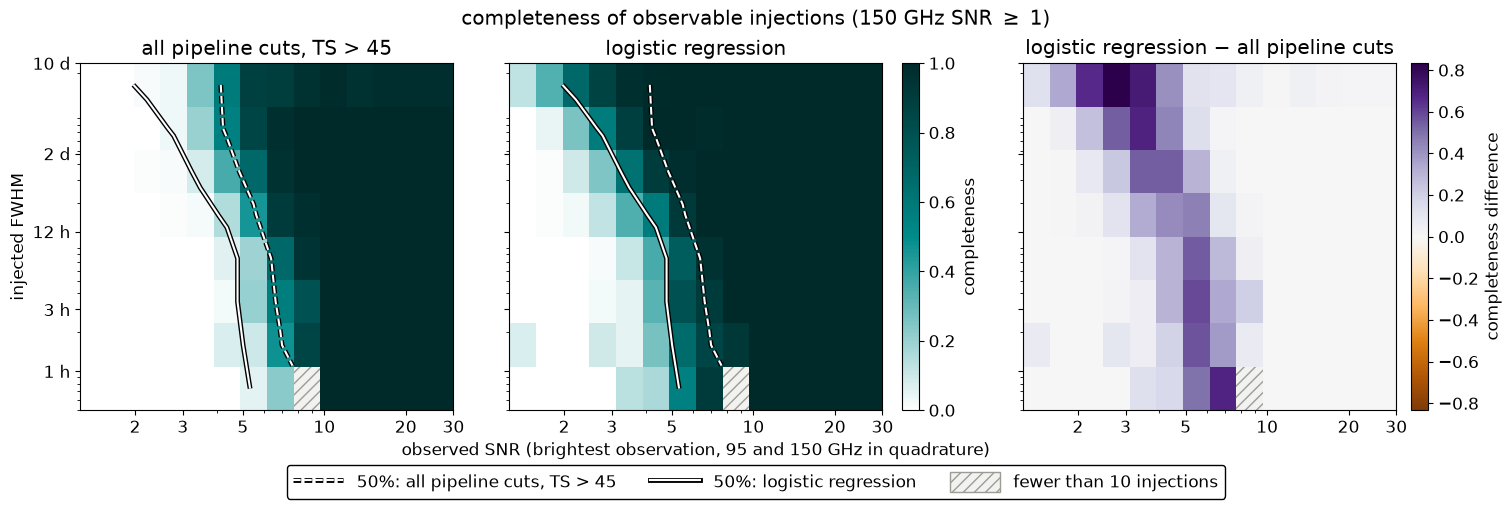

In [91]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import matplotlib.patheffects as path_effects
from matplotlib.colors import LinearSegmentedColormap

# 2D completeness over observed SNR x injected FWHM: pipeline and logistic regression side by side on one
# color scale, then their difference. cells with fewer than 10 injections are hatched instead of colored
fwhm_bin_edges = np.geomspace(0.5, 240, 9) # hours: 30 min to 10 days
fwhm_bin_centers = np.sqrt(fwhm_bin_edges[:-1] * fwhm_bin_edges[1:])
min_injections = 10
sparse_style = {'facecolor': '#f2f2f0', 'edgecolor': '#9c9b95', 'hatch': '///'}

total, _, _ = np.histogram2d(observed_snr, injected_fwhm_hours, bins=[snr_bin_edges, fwhm_bin_edges])

def completeness_grid(detected):
    found, _, _ = np.histogram2d(observed_snr[detected], injected_fwhm_hours[detected],
                                 bins=[snr_bin_edges, fwhm_bin_edges])
    with np.errstate(invalid='ignore'):
        return np.where(total >= min_injections, found / total, np.nan)

grids = {name: completeness_grid(detected[name]) for name in ['ts_positive_fwhm_pixel_45', 'logistic']}
contour_styles = {'ts_positive_fwhm_pixel_45': '--', 'logistic': '-'}
contour_outline = [path_effects.withStroke(linewidth=3.5, foreground='k')] # white contour lines with a black outline
completeness_cmap = LinearSegmentedColormap.from_list('white_to_cyan', ['white', 'darkcyan', '#002a2a'])

with plt.rc_context({'font.size': 12}):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True, layout='constrained')
    for ax in axes:
        # hatched background shows through the empty (sparse) cells
        ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, lw=0, zorder=-1, **sparse_style))

    # the two completeness maps, both 50% boundaries drawn on each for comparison
    for ax, name in zip(axes[:2], ['ts_positive_fwhm_pixel_45', 'logistic']):
        mesh = ax.pcolormesh(snr_bin_edges, fwhm_bin_edges, grids[name].T, cmap=completeness_cmap, vmin=0, vmax=1)
        for contour_name, linestyle in contour_styles.items():
            # white line with a black outline, so the boundary shows on both light and dark cells
            contour = ax.contour(snr_bin_centers, fwhm_bin_centers, grids[contour_name].T, levels=[0.5],
                                 colors='white', linestyles=linestyle, linewidths=1.5)
            contour.set_path_effects(contour_outline)
        ax.set_title(pltfun.METHOD_STYLES[name]['label'])
    fig.colorbar(mesh, ax=axes[:2], label='completeness', pad=0.01)

    # difference map, centered at zero (purple: logistic regression finds more, orange: the pipeline finds more)
    difference = grids['logistic'] - grids['ts_positive_fwhm_pixel_45']
    limit = np.nanmax(np.abs(difference))
    mesh = axes[2].pcolormesh(snr_bin_edges, fwhm_bin_edges, difference.T, cmap='PuOr', vmin=-limit, vmax=limit)
    fig.colorbar(mesh, ax=axes[2], label='completeness difference', pad=0.01)
    # extra space between the completeness colorbar and the difference panel, so its label doesn't read as that panel's axis label
    fig.get_layout_engine().set(wspace=0.08)
    axes[2].set_title('logistic regression $-$ all pipeline cuts')

    for ax in axes:
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xticks([2, 3, 5, 10, 20, 30], labels=['2', '3', '5', '10', '20', '30'])
        ax.xaxis.set_minor_formatter(plt.NullFormatter()) # no labels on the minor log ticks
        ax.set_yticks([1, 3, 12, 48, 240], labels=['1 h', '3 h', '12 h', '2 d', '10 d'])
    axes[0].set_ylabel('injected FWHM')
    # one shared x label under the middle panel (fig.supxlabel gets covered by the outside legend)
    axes[1].set_xlabel('observed SNR (brightest observation, 95 and 150 GHz in quadrature)')
    fig.suptitle('completeness of observable injections (150 GHz SNR $\\geq$ 1)')

    # legend below the panels so it doesn't cover any cells
    legend_handles = [
        Line2D([], [], color='white', ls='--', path_effects=contour_outline,
               label=f"50%: {pltfun.METHOD_STYLES['ts_positive_fwhm_pixel_45']['label']}"),
        Line2D([], [], color='white', ls='-', path_effects=contour_outline,
               label=f"50%: {pltfun.METHOD_STYLES['logistic']['label']}"),
        Patch(label=f"fewer than {min_injections} injections", **sparse_style),
    ]
    fig.legend(handles=legend_handles, loc='outside lower center', ncols=3, edgecolor='k', framealpha=1,
               handlelength=3, handleheight=1.5)
    plt.savefig(f"{image_dir}/evaluation/completeness_maps.png", dpi=150, bbox_inches='tight')

#### disagreement analysis: logistic vs TS without the pixel significance cut

In [92]:
# bootstrapping showed logistic regression worked slightly better on detecting injected flares compared to the TS fitter without the
# pixel significance selection. let's investigate the actual flares it found to answer the questions:
#   - did it perform slightly better in all flare morphologies or is it a tradeoff in some?
#   - does it also show a spectral index bias like the GBM methods?

positives = positives.with_columns(
    (pl.col('logistic_score') > noise_threshold['logistic_score']).alias('logistic_detected'),
    (pl.col('ts_positive_score') > noise_threshold['ts_positive_score']).alias('ts_positive_detected'),
    (pl.col('inj_fwhm_d') * 24).alias('inj_fwhm_hours'),
)

# agreement table
print(positives.group_by('logistic_detected', 'ts_positive_detected').agg(pl.len().alias('N'))
      .sort('logistic_detected', 'ts_positive_detected'))

# rates instead of absolute values, by observed SNR, injected FWHM and true spectral index
def rates_by_bin(column, edges, label):
    return (positives
            .with_columns(ev.bin_series(positives[column], edges, label))
            .group_by(label)
            .agg(pl.len().alias('N'),
                 pl.col('logistic_detected').mean().alias('logistic_recall'),
                 pl.col('ts_positive_detected').mean().alias('ts_positive_recall'),
                 (pl.col('logistic_detected') & ~pl.col('ts_positive_detected')).mean().alias('logistic_only_frac'),
                 (~pl.col('logistic_detected') & pl.col('ts_positive_detected')).mean().alias('ts_positive_only_frac'))
            .with_columns((pl.col('logistic_recall') - pl.col('ts_positive_recall')).alias('recall_difference'))
            .sort(label))

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250):
    print(rates_by_bin('inj_max_obs_snr_150', [1, 2, 3, 4, 5, 7, 10], 'observed_snr_bin'))
    print(rates_by_bin('inj_fwhm_hours', [1, 3, 12, 48, 120], 'fwhm_hours_bin'))
    print(rates_by_bin('inj_alpha', [-1, -0.5, 0, 0.5, 1], 'true_alpha_bin'))

shape: (4, 3)
┌───────────────────┬──────────────────────┬──────┐
│ logistic_detected ┆ ts_positive_detected ┆ N    │
│ ---               ┆ ---                  ┆ ---  │
│ bool              ┆ bool                 ┆ u32  │
╞═══════════════════╪══════════════════════╪══════╡
│ false             ┆ false                ┆ 2066 │
│ false             ┆ true                 ┆ 10   │
│ true              ┆ false                ┆ 149  │
│ true              ┆ true                 ┆ 8608 │
└───────────────────┴──────────────────────┴──────┘
shape: (7, 7)
┌──────────────────┬──────┬─────────────────┬────────────────────┬────────────────────┬───────────────────────┬───────────────────┐
│ observed_snr_bin ┆ N    ┆ logistic_recall ┆ ts_positive_recall ┆ logistic_only_frac ┆ ts_positive_only_frac ┆ recall_difference │
│ ---              ┆ ---  ┆ ---             ┆ ---                ┆ ---                ┆ ---                   ┆ ---               │
│ enum             ┆ u32  ┆ f64             ┆ f64       

### fixed alpha test

In [93]:
# how much does completeness depend on a flare's spectral index? including the constantly-asked question of the impact of the pixel significance cut
# how do the classifiers behave on spectra outside of the training set?
# to answer this, we'll perform more injections in different spectral index bins using the same population of flares

fixed_alphas = [-2.0, -1.0, 0.0, 1.0, 2.0, 3.0]
n_per_alpha = 3000
hosts = negatives.select('gaia_id', 'window_start')

def run_fixed_alpha():
    fixed_alpha_tables = []
    for alpha in fixed_alphas:
        # same seed for every alpha: identical hosts, times, widths and SNRs; only the spectrum differs.
        # 'combined' normalization keeps the quadrature-combined peak SNR fixed, so alpha changes
        # the spectral shape at fixed total significance.
        injections = dataset.draw_injections(hosts, n_injections=n_per_alpha, alpha_pool=[alpha], seed=100)
        fixed_alpha_tables.append(dataset.fit_injections(injections, lightcurves, normalization='combined'))
    return pl.concat(fixed_alpha_tables).filter(pl.col('inj_max_obs_snr_combined') >= 1)   # observable only

injection_columns = ['inj_id', 'gaia_id', 'window_start', 'inj_t0_rel_d', 'inj_fwhm_d', 'inj_snr_peak',
                     'inj_alpha', 'inj_amp_95', 'inj_amp_150', 'inj_max_obs_snr_150', 'inj_max_obs_snr_combined']
fixed_alpha_fits = (load_or_run(f"{data_dir}/fixed_alpha_test.parquet", run_fixed_alpha)
                    .select(*injection_columns, *window_feature_columns)
                    .with_columns(log_ts))

# score each window with the model that never saw its star, then save with the scores
fixed_alpha_fits = ev.ts_scores(score_with_fold_models(fixed_alpha_fits))
fixed_alpha_fits.write_parquet(f"{data_dir}/fixed_alpha_test.parquet")

# completeness by alpha: all observable injections, then only observed combined SNR 2-5
detected = [(pl.col(m) > noise_threshold[m]).mean().alias(m.replace('_score', '')) for m in methods]
pipeline_rules_45 = (pl.col('ts_positive_fwhm_pixel_score') > 45).mean().alias('ts_positive_fwhm_pixel_45')
near_threshold = pl.col('inj_max_obs_snr_combined').is_between(2, 5)
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250):
    print(fixed_alpha_fits.group_by('inj_alpha')
          .agg(pl.len().alias('N'), pipeline_rules_45, *detected).sort('inj_alpha'))
    print(fixed_alpha_fits.filter(near_threshold)
          .group_by('inj_alpha').agg(pl.len().alias('N'), pipeline_rules_45, *detected).sort('inj_alpha'))

shape: (6, 9)
┌───────────┬──────┬───────────────────────────┬────────────────────────┬──────────────────┬─────────────┬──────────┬──────────┬───────────┐
│ inj_alpha ┆ N    ┆ ts_positive_fwhm_pixel_45 ┆ ts_positive_fwhm_pixel ┆ ts_positive_fwhm ┆ ts_positive ┆ logistic ┆ gbm      ┆ gbm_no_ts │
│ ---       ┆ ---  ┆ ---                       ┆ ---                    ┆ ---              ┆ ---         ┆ ---      ┆ ---      ┆ ---       │
│ f64       ┆ u32  ┆ f64                       ┆ f64                    ┆ f64              ┆ f64         ┆ f64      ┆ f64      ┆ f64       │
╞═══════════╪══════╪═══════════════════════════╪════════════════════════╪══════════════════╪═════════════╪══════════╪══════════╪═══════════╡
│ -2.0      ┆ 1668 ┆ 0.528177                  ┆ 0.532974               ┆ 0.691847         ┆ 0.696643    ┆ 0.702038 ┆ 0.643885 ┆ 0.645084  │
│ -1.0      ┆ 1665 ┆ 0.581982                  ┆ 0.595195               ┆ 0.693093         ┆ 0.698498    ┆ 0.70991  ┆ 0.664865 ┆ 0.675075  │

In [94]:
# what does the pixel significance cut alone cost? both versions at the pipeline's TS > 45 (no re-tuning), with
# positive amplitudes and FWHM < 10 d; only the pixel significance cut differs
with_cut, without_cut = 'ts_positive_fwhm_pixel_score', 'ts_positive_fwhm_score'

def completeness_ts45(df):
    return {m: (df[m] > 45).mean() for m in [with_cut, without_cut]}

rows = [
    {'sample': 'noise windows passing (count)', 'N': mirrored.height,
     **{m: float((mirrored[m] > 45).sum()) for m in [with_cut, without_cut]}},
    {'sample': 'overall (main injections)', 'N': positives.height, **completeness_ts45(positives)},
]
for label, sample in [('alpha = 0', pl.col('inj_alpha') == 0),
                      ('|alpha| = 1', pl.col('inj_alpha').abs() == 1),
                      ('|alpha| = 2', pl.col('inj_alpha').abs() == 2),
                      ('alpha = 3', pl.col('inj_alpha') == 3)]:
    for snr_label, snr_cut in [('all SNR', pl.lit(True)), ('near threshold', near_threshold)]:
        subset = fixed_alpha_fits.filter(sample & snr_cut)
        rows.append({'sample': f"{snr_label}, {label}", 'N': subset.height, **completeness_ts45(subset)})

pixel_sig_completeness = (
    pl.DataFrame(rows)
    .rename({with_cut: 'with_cut', without_cut: 'without_cut'})
    .with_columns(((pl.col('without_cut') - pl.col('with_cut')) * 100).alias('percentage_point_increase'))
    .with_columns(pl.col(pl.Float64).round(3))
)
pixel_sig_completeness

sample,N,with_cut,without_cut,percentage_point_increase
str,i64,f64,f64,f64
"""noise windows passing (count)""",10650,0.0,0.0,0.0
"""overall (main injections)""",10833,0.693,0.733,4.016
"""all SNR, alpha = 0""",1665,0.599,0.638,3.964
"""near threshold, alpha = 0""",388,0.119,0.268,14.948
"""all SNR, |alpha| = 1""",3331,0.585,0.64,5.464
"""near threshold, |alpha| = 1""",781,0.087,0.273,18.566
"""all SNR, |alpha| = 2""",3332,0.534,0.639,10.534
"""near threshold, |alpha| = 2""",783,0.043,0.28,23.627
"""all SNR, alpha = 3""",1665,0.462,0.64,17.778


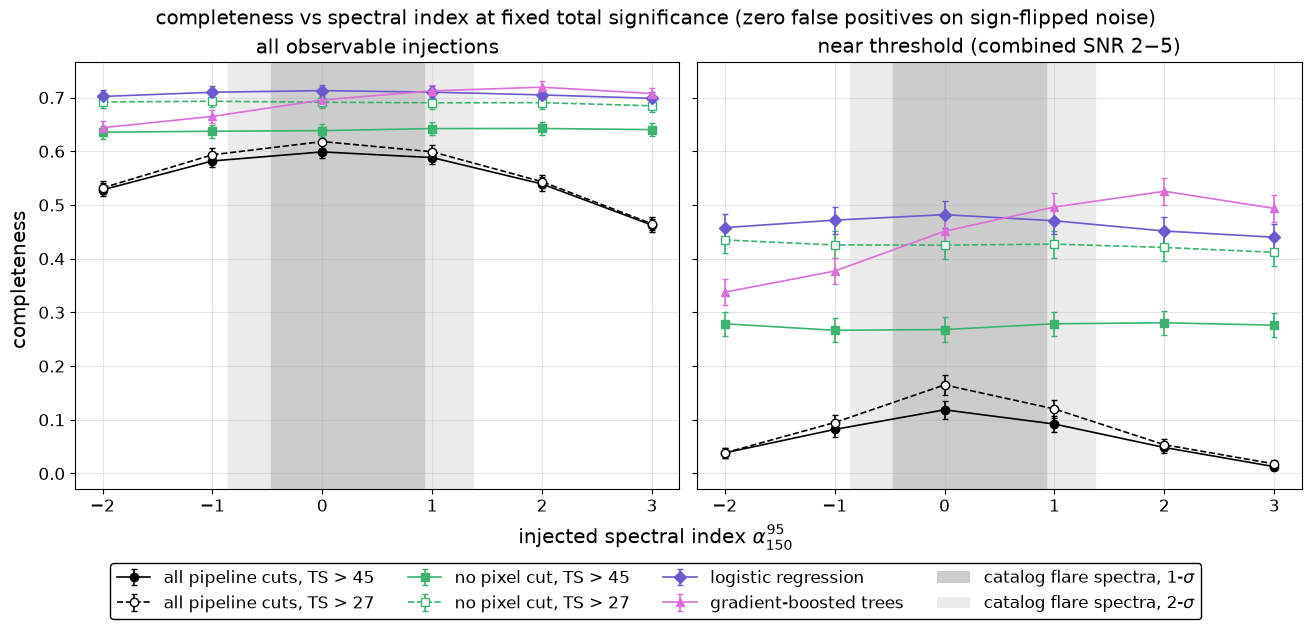

In [100]:
from matplotlib.patches import Patch

# completeness vs injected spectral index at fixed total significance (combined-SNR normalization), for all
# observable injections and near threshold. thresholds as in the completeness figures: the pipeline's TS > 45,
# TS lowered to the zero-noise-FP level without the pixel cut (~27), and the models at their own zero-noise-FP
# thresholds. the shaded band is where most catalog flares' spectra fall
lowered_ts = noise_threshold['ts_positive_fwhm_score']
fixed_alpha_detected = {
    'ts_positive_fwhm_pixel_45': pl.col('ts_positive_fwhm_pixel_score') > 45,
    'ts_positive_fwhm_pixel_27': pl.col('ts_positive_fwhm_pixel_score') > lowered_ts,
    'ts_positive_fwhm_45': pl.col('ts_positive_fwhm_score') > 45,
    'ts_positive_fwhm_27': pl.col('ts_positive_fwhm_score') > lowered_ts,
    'logistic': pl.col('logistic_score') > noise_threshold['logistic_score'],
    'gbm': pl.col('gbm_score') > noise_threshold['gbm_score'],
}
catalog_alpha = catalog.filter(pl.col('spectral_index_95_150').is_finite())['spectral_index_95_150'].to_numpy()
# catalog spectral index ranges, as percentiles (1-sigma: 16th-84th, 2-sigma: 2.3rd-97.7th)
catalog_bands = {
    '1 sigma': {'range': np.percentile(catalog_alpha, [16, 84]), 'color': '0.8', 'label': '1-$\\sigma$'},
    '2 sigma': {'range': np.percentile(catalog_alpha, [2.3, 97.7]), 'color': '0.92', 'label': '2-$\\sigma$'},
}

with plt.rc_context({'font.size': 12}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True, layout='constrained')
    samples = [('all observable injections', pl.lit(True)), ('near threshold (combined SNR 2$-$5)', near_threshold)]
    for ax, (title, sample) in zip(axes, samples):
        rates = (fixed_alpha_fits.filter(sample)
                 .group_by('inj_alpha')
                 .agg(pl.len().alias('N'), *[detected.mean().alias(name) for name, detected in fixed_alpha_detected.items()])
                 .sort('inj_alpha'))
        alphas, n_injections = rates['inj_alpha'].to_numpy(), rates['N'].to_numpy()
        for band in [catalog_bands['2 sigma'], catalog_bands['1 sigma']]:
            ax.axvspan(*band['range'], color=band['color'], zorder=0)
        for name in fixed_alpha_detected:
            style = pltfun.METHOD_STYLES[name]
            fraction = rates[name].to_numpy()
            error = np.sqrt(fraction * (1 - fraction) / n_injections) # binomial
            ax.errorbar(alphas, fraction, yerr=error, fmt=style['marker'], ls='--' if style['open'] else '-',
                        ms=6, lw=1.2, capsize=2, color=style['color'],
                        mfc='white' if style['open'] else style['color'], label=style['label'])
        ax.set_title(title)
        ax.set_xticks(fixed_alphas)
        ax.grid(alpha=0.3)

    legend_handles, _ = axes[0].get_legend_handles_labels()
    legend_handles += [Patch(facecolor=band['color'], label=f"catalog flare spectra, {band['label']}")
                       for band in catalog_bands.values()]
    fig.supxlabel('injected spectral index $\\alpha^{95}_{150}$')
    fig.supylabel('completeness')
    fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0), ncols=4, edgecolor='k', framealpha=1)
    fig.suptitle('completeness vs spectral index at fixed total significance (zero false positives on sign-flipped noise)')
    plt.savefig(f"{image_dir}/evaluation/fixed_alpha.png", dpi=150, bbox_inches='tight')

# SQL/Docker stuff

In [126]:
# confirming the SQL pipeline reproduces the training set as what's in the dataframes
# (run load_db.py first so the database is built from the current parquet files)

with db.connect() as conn:
    sql_dataset = db.query_df(conn, 'SELECT * FROM dataset')

parquet_dataset = pl.read_parquet(f"{data_dir}/dataset.parquet")
compare_columns = parquet_dataset.columns

print(sql_dataset.group_by('source', 'label').agg(pl.len().alias('N')).sort('label'))

# negatives are matched by window, positives by injection
for source, key in [('quiescent', ['gaia_id', 'window_start']), ('injection', ['inj_id'])]:
    expected = parquet_dataset.filter(pl.col('source') == source).sort(key)
    result = sql_dataset.filter(pl.col('source') == source).sort(key).select(compare_columns)
    assert_frame_equal(expected, result, check_dtypes=False)
    print(f"{source}: {result.height} rows match")

shape: (2, 3)
┌───────────┬───────┬───────┐
│ source    ┆ label ┆ N     │
│ ---       ┆ ---   ┆ ---   │
│ str       ┆ i64   ┆ u32   │
╞═══════════╪═══════╪═══════╡
│ quiescent ┆ 0     ┆ 10650 │
│ injection ┆ 1     ┆ 10833 │
└───────────┴───────┴───────┘
quiescent: 10650 rows match
injection: 10833 rows match
